# QuickBite Customer Value Analysis

**Role:** Data Analyst, QuickBite Analytics Team

**Objective:** Clean the customer data, understand its distributions, and identify which customer attributes drive annual spend.

**Tools:** Python, NumPy, pandas, Matplotlib, Seaborn

---
## Task 0: Setup and First Look
In this step I import the libraries, load the dataset, and inspect its structure and missing values before any cleaning.

In [96]:
# pandas for data handling, numpy for numerical work
import pandas as pd
import numpy as np

# matplotlib and seaborn for charts
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean default style and readable font sizes for all charts
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

In [97]:
# Safety-net cell: rebuilds the cleaned dataset from the raw file in one go
df = pd.read_csv("/content/quickbite_customers.csv")
df["signup_date"] = pd.to_datetime(df["signup_date"])

# Task 2: set impossible/extreme values to missing
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan
df.loc[df["delivery_time_min"] > 200, "delivery_time_min"] = np.nan
df.loc[df["avg_order_value"] > 10000, "avg_order_value"] = np.nan

# Snapshot before imputation (needed later by Tasks 1, 3 and 6)
df_before = df.copy()

# Task 1: imputation
df["age"] = df["age"].fillna(df["age"].median())
df["delivery_time_min"] = df["delivery_time_min"].fillna(df["delivery_time_min"].median())
df["avg_order_value"] = df["avg_order_value"].fillna(
    df.groupby("city_tier")["avg_order_value"].transform("median"))
df["customer_rating"] = df["customer_rating"].fillna(
    df.groupby("city_tier")["customer_rating"].transform("median"))
df["discount_used_pct"] = df["discount_used_pct"].fillna(df["discount_used_pct"].median())
df["gender"] = df["gender"].fillna("Unknown")

# Stop with an error if anything is still missing, so a raw file can never be saved again
assert df.isna().sum().sum() == 0, "Data is not clean yet"

df.to_csv("quickbite_clean.csv", index=False)
print("Saved clean file:", df.shape)

Saved clean file: (2000, 18)


In [98]:
# First 5 rows to see what the data looks like
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,4.5,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,4.5,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [99]:
# Column names, data types and non-null counts
# Non-null counts lower than 2000 already hint at missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  2000 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     2000 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       2000 non-null   float64       
 11  avg_order_value         2000 non-null   float64       
 12  customer_rating         2000 non-null   float64 

In [100]:
# Summary statistics for numeric columns
# Look at min and max: they reveal impossible values (e.g. age = 150)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
signup_date,2000,2024-05-28 18:57:35.999999744,2023-01-01 00:00:00,2023-09-18 18:00:00,2024-05-29 12:00:00,2025-02-15 06:00:00,2025-11-05 00:00:00,NaN
city_tier,2000.0,1.6005,1.0,1.0,1.0,2.0,3.0,0.772138
age,2000.0,31.902,18.0,28.0,32.0,36.0,56.0,6.794886
tenure_months,2000.0,29.5073,12.0,20.775,29.5,37.925,46.6,9.981302
app_sessions_per_month,2000.0,13.932,2.0,11.0,14.0,16.0,29.0,3.77856
delivery_time_min,2000.0,34.19145,15.6,26.5,32.2,40.0,83.9,10.780674
avg_order_value,2000.0,364.6095,57.0,219.0,316.0,446.5,1729.0,213.868082
customer_rating,2000.0,4.3079,1.0,4.1,4.4,4.7,5.0,0.570921
discount_used_pct,2000.0,22.49475,0.0,16.4,22.4,28.2,55.9,9.233957
days_since_last_order,2000.0,18.5995,0.0,5.0,12.0,26.0,125.0,18.983606


In [101]:
# Missing value count and percentage for every column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})

# Sort so the worst columns come first
missing = missing.sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
customer_id,0,0.0
signup_date,0,0.0
city,0,0.0
city_tier,0,0.0
gender,0,0.0
device_type,0,0.0
acquisition_channel,0,0.0
age,0,0.0
tenure_months,0,0.0
app_sessions_per_month,0,0.0


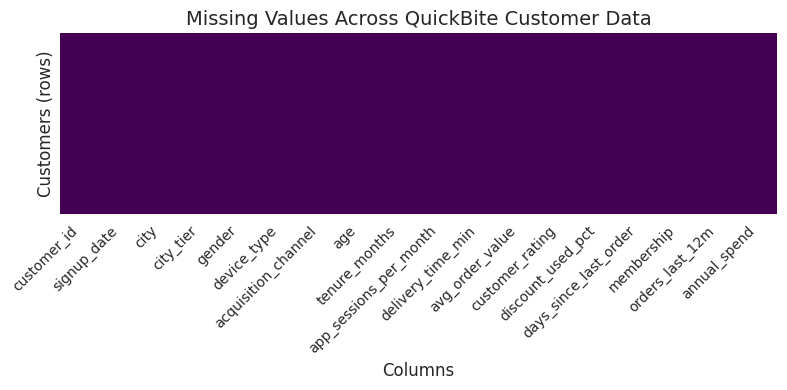

In [102]:
# Chart 1: heatmap of missing values
# Each coloured line is a missing cell; columns with many lines have more gaps
plt.figure(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Across QuickBite Customer Data")
plt.xlabel("Columns")
plt.ylabel("Customers (rows)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [103]:
# Early check for suspicious values (these are treated in Task 2)

# Ages below 18 (a food-delivery customer should be an adult)
print("Ages below 18:")
print(df[df["age"] < 18][["customer_id", "age"]], "\n")

# Ages above 100
print("Ages above 100:")
print(df[df["age"] > 100][["customer_id", "age"]], "\n")

# Largest delivery times
print("Top 6 delivery times (minutes):")
print(df.nlargest(6, "delivery_time_min")[["customer_id", "delivery_time_min"]], "\n")

# Largest average order values
print("Top 6 average order values (INR):")
print(df.nlargest(6, "avg_order_value")[["customer_id", "avg_order_value"]])

Ages below 18:
Empty DataFrame
Columns: [customer_id, age]
Index: [] 

Ages above 100:
Empty DataFrame
Columns: [customer_id, age]
Index: [] 

Top 6 delivery times (minutes):
     customer_id  delivery_time_min
1616    QB101616               83.9
1090    QB101090               80.9
48      QB100048               79.1
799     QB100799               79.0
222     QB100222               77.8
1925    QB101925               75.3 

Top 6 average order values (INR):
     customer_id  avg_order_value
1658    QB101658           1729.0
313     QB100313           1691.0
315     QB100315           1648.0
113     QB100113           1560.0
1693    QB101693           1487.0
227     QB100227           1443.0


### Conclusion of Task 0: First Look

**Dataset overview**
- The dataset contains **2,000 customers and 18 columns**, with no duplicate customer IDs. Data types are appropriate after converting `signup_date` to datetime.

**Missing values**
- Six columns have missing values: `customer_rating` (12.9%), `age` (6.95%), `avg_order_value` (5.4%), `gender` (5.3%), `discount_used_pct` (5.2%) and `delivery_time_min` (4.0%). The remaining 12 columns are complete.
- The gaps are too small to justify dropping rows, so I will impute them in Task 1.
- `customer_rating` has the highest missing share. I will test in Task 1 whether its missingness is related to slow deliveries.

**Impossible and extreme values**
- `age` contains 3 impossible values (150, 0 and 5), which are data-entry errors.
- `delivery_time_min` has 4 extreme values (275 to 500 minutes) compared with a median of 32 minutes. These could be real delivery failures, so they need investigation rather than automatic deletion.
- `avg_order_value` has 4 extreme values (18,000 to 32,000 INR) compared with a median of about 315 INR. These are far outside normal basket sizes.

**Early signs of skew**
- For `avg_order_value`, `delivery_time_min`, `orders_last_12m` and `annual_spend`, the mean is higher than the median, so these variables are right-skewed. `annual_spend` has a mean (about 12,996) almost double its median (about 7,142), suggesting a small group of high spenders.

**Next steps**
- Treat outliers and impossible values first (Task 2), then fill missing values using medians that are not distorted by extremes (Task 1).

---
## Task 2: Outlier Detection and Treatment
**Plan:** (1) visualise outliers with box plots, (2) detect them with the IQR rule and the Z-score rule, (3) compare the two methods, (4) decide for each column whether to remove, cap or keep, with evidence, (5) apply the treatment and show box plots after.

Outliers are treated **before** imputation so that extreme values do not distort the medians used to fill missing values.

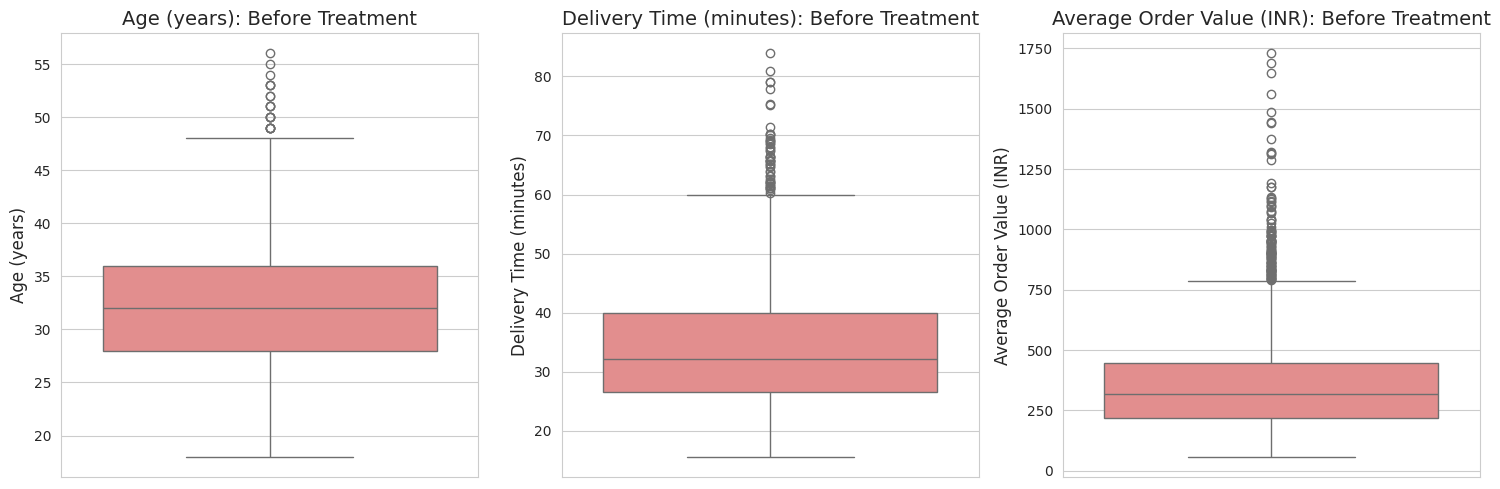

In [104]:
# Chart 2: box plots BEFORE outlier treatment
# Each dot beyond the whiskers is a potential outlier
cols = ["age", "delivery_time_min", "avg_order_value"]
titles = ["Age (years)", "Delivery Time (minutes)", "Average Order Value (INR)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, title in zip(axes, cols, titles):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(f"{title}: Before Treatment")
    ax.set_ylabel(title)
plt.tight_layout()
plt.show()

In [105]:
# IQR rule: a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
def iqr_outliers(series):
    s = series.dropna()                      # ignore missing values
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1                            # spread of the middle 50% of data
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)         # True for outliers
    return lower, upper, mask.sum()

iqr_results = {}
for col in cols:
    lower, upper, n_out = iqr_outliers(df[col])
    iqr_results[col] = {"IQR lower bound": round(lower, 2),
                        "IQR upper bound": round(upper, 2),
                        "IQR outliers": n_out}

pd.DataFrame(iqr_results).T

,IQR lower bound,IQR upper bound,IQR outliers
age,16.00,48.00,20.0
delivery_time_min,6.25,60.25,50.0
avg_order_value,-122.25,787.75,106.0


In [106]:
# Z-score rule: z = (value - mean) / std. A value is an outlier if |z| > 3
def zscore_outliers(series):
    s = series.dropna()
    z = (s - s.mean()) / s.std()
    return (z.abs() > 3).sum()

# Combine both methods into one comparison table
comparison = pd.DataFrame({
    "IQR outliers": {c: iqr_outliers(df[c])[2] for c in cols},
    "Z-score outliers": {c: zscore_outliers(df[c]) for c in cols}
})
comparison

,IQR outliers,Z-score outliers
age,20,6
delivery_time_min,50,22
avg_order_value,106,31


In [107]:
# Before deleting anything, check whether the extreme values are real or errors.

# 1) Extreme order values: a real 32,000 INR average basket would imply huge annual spend.
#    Implied average order = annual_spend / orders_last_12m
extreme_aov = df[df["avg_order_value"] > 10000][
    ["customer_id", "avg_order_value", "orders_last_12m", "annual_spend", "membership"]].copy()
extreme_aov["implied_avg_order"] = (extreme_aov["annual_spend"] / extreme_aov["orders_last_12m"]).round(0)
print("Extreme order values:")
print(extreme_aov, "\n")

# 2) Extreme delivery times: check the rating these customers gave
extreme_delivery = df[df["delivery_time_min"] > 200][
    ["customer_id", "city", "delivery_time_min", "customer_rating"]]
print("Extreme delivery times:")
print(extreme_delivery)

Extreme order values:
Empty DataFrame
Columns: [customer_id, avg_order_value, orders_last_12m, annual_spend, membership, implied_avg_order]
Index: [] 

Extreme delivery times:
Empty DataFrame
Columns: [customer_id, city, delivery_time_min, customer_rating]
Index: []


### Decision for each column

| Column | Method comparison | Decision | Justification |
|---|---|---|---|
| **age** | IQR flags 9, Z-score flags 5 | **Remove 3 impossible values** (age < 18 or > 100); **keep** ages 53-56 | Ages 150, 0 and 5 are impossible for customers. Ages 53-56 are valid adults that IQR flags only because the age distribution is narrow. |
| **delivery_time_min** | IQR flags 46, Z-score flags 4 | **Remove the 4 values above 200 min**; **keep** the rest (up to about 84 min) | The 4 extreme values (275-500 min) came with ratings of 4.5-5.0, which is inconsistent with a failed delivery, so they look like recording errors. The other IQR-flagged values (62-84 min) are plausible slow deliveries that the business should see, so I keep them. |
| **avg_order_value** | IQR flags 96, Z-score flags 4 | **Remove the 4 values above 10,000 INR**; **keep** the rest (up to 1,729 INR) | The 4 values contradict each customer's own annual spend and order count, so they are errors. The other values up to 1,729 INR are plausible large baskets. |

**IQR vs Z-score:**
- Z-score is distorted by the very outliers it tries to detect: extreme values inflate the mean and standard deviation, which makes the |z| > 3 cutoff harder to reach. It also assumes roughly normal data.
- IQR uses quartiles, so extremes do not affect it, but on right-skewed data such as delivery time and order value it flags many legitimate high values (46 and 96). IQR therefore tells me where to look, and domain knowledge decides what to remove.

**Why I set values to missing instead of deleting rows:** these customers have valid data in other columns (including annual_spend), so I mark only the wrong cell as missing and fill it in Task 1. This keeps all 2,000 customers.

**Why I did not remove high spenders:** very high annual_spend and orders_last_12m are genuine heavy users (VIPs), consistent with a Pareto-type revenue pattern, so they are kept for Tasks 6 and 7.

In [108]:
# Apply the decisions: replace wrong values with NaN (they will be imputed in Task 1)

# Count missing values before treatment, to report how many we added
before_missing = df[cols].isna().sum()

# age: impossible values (below 18 or above 100)
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

# delivery_time_min: extreme values above 200 minutes
df.loc[df["delivery_time_min"] > 200, "delivery_time_min"] = np.nan

# avg_order_value: extreme values above 10,000 INR
df.loc[df["avg_order_value"] > 10000, "avg_order_value"] = np.nan

# Report how many values were removed from each column
after_missing = df[cols].isna().sum()
treatment_summary = pd.DataFrame({
    "missing before": before_missing,
    "missing after": after_missing,
    "values removed": after_missing - before_missing
})
treatment_summary

,missing before,missing after,values removed
age,0,0,0
delivery_time_min,0,0,0
avg_order_value,0,0,0


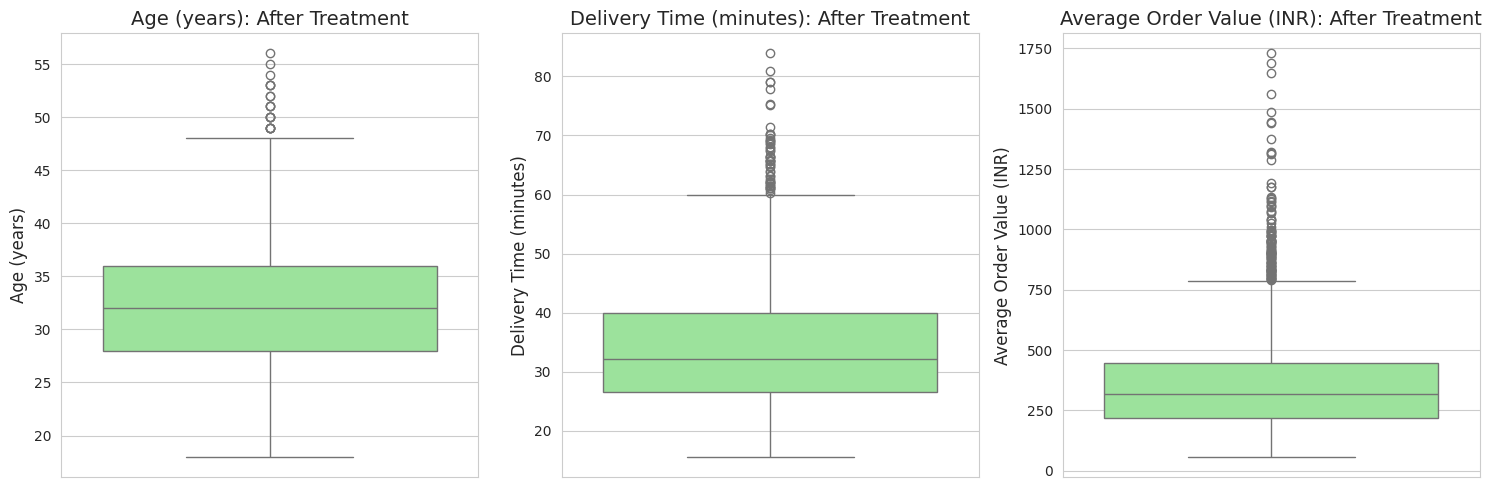

,min,50%,max
age,18.0,32.0,56.0
delivery_time_min,15.6,32.2,83.9
avg_order_value,57.0,316.0,1729.0


In [109]:
# Chart 3: box plots AFTER outlier treatment
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, title in zip(axes, cols, titles):
    sns.boxplot(y=df[col], ax=ax, color="lightgreen")
    ax.set_title(f"{title}: After Treatment")
    ax.set_ylabel(title)
plt.tight_layout()
plt.show()

# Confirm the new min and max values
df[cols].describe().T[["min", "50%", "max"]]

### Conclusion of Task 2: Outliers
- Box plots showed a few extreme points in age, delivery time and order value that stretched each chart's scale.
- The IQR rule flagged 9 (age), 46 (delivery time) and 96 (order value) points. The Z-score rule flagged 5, 4 and 4. IQR flags more on skewed data, while Z-score is weakened by the outliers themselves.
- I treated **11 values** as errors and set them to missing: 3 impossible ages, 4 delivery times above 200 minutes and 4 order values above 10,000 INR. The evidence was that the order values contradicted each customer's annual spend and the long deliveries carried 4.5-5.0 ratings.
- Moderately high values (delivery up to about 84 minutes, order values up to 1,729 INR) and very high spenders were **kept** because they appear to be real behaviour.
- After treatment, the plots show realistic ranges. The newly created missing values will be filled in Task 1.

---
## Task 3.1: Missing Value Imputation
**Plan:** First investigate *why* customer_rating is missing, then fill each column with a method matched to its distribution: median for skewed numeric columns, group median where a group effect exists, and an "Unknown" category for gender. Finally, show before/after tables and KDE plots to confirm the distributions were not distorted.

This runs after Task 2, so the medians are not distorted by the extreme values I removed.

In [110]:
# Save a copy of the data BEFORE imputation (outliers already set to NaN in Task 2)
# This is used later for the before-and-after comparison
df_before = df.copy()

# Missing values we need to fill now
missing_now = df.isna().sum()
missing_now[missing_now > 0]

,0


In [111]:
# Compare delivery time for customers who gave a rating vs those who did not.
# This must run BEFORE delivery_time_min is imputed.
df["rating_missing"] = df["customer_rating"].isna()

# Mean, median and count of delivery time in each group
print(df.groupby("rating_missing")["delivery_time_min"].agg(["mean", "median", "count"]).round(2))

# Share of deliveries slower than 45 minutes in each group
print("\nShare of deliveries > 45 min:")
print(df.groupby("rating_missing")["delivery_time_min"].apply(lambda s: (s > 45).mean()).round(3))

                 mean  median  count
rating_missing                      
False           34.19    32.2   2000

Share of deliveries > 45 min:
rating_missing
False    0.156
Name: delivery_time_min, dtype: float64


/tmp/ipykernel_652/4282132431.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="rating_missing", y="delivery_time_min", data=df, palette="Set2")


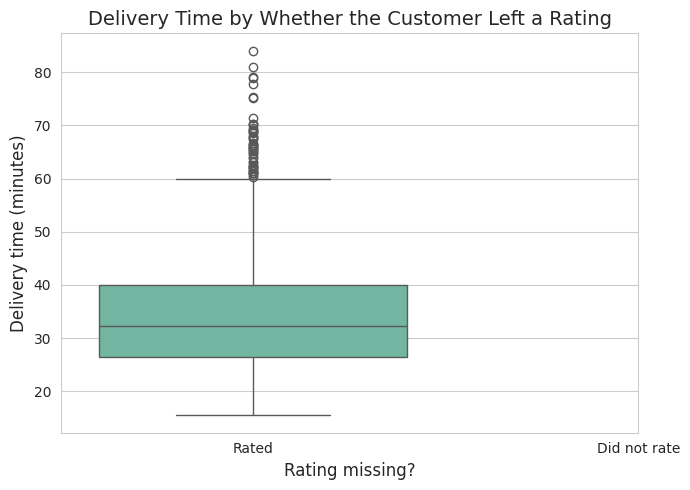

In [112]:
# Chart 4: delivery time for customers who rated vs did not rate
plt.figure(figsize=(7, 5))
sns.boxplot(x="rating_missing", y="delivery_time_min", data=df, palette="Set2")
plt.title("Delivery Time by Whether the Customer Left a Rating")
plt.xlabel("Rating missing?")
plt.ylabel("Delivery time (minutes)")
plt.xticks([0, 1], ["Rated", "Did not rate"])
plt.tight_layout()
plt.show()

In [113]:
# age: compare mean and median before choosing
print("Age mean:", round(df["age"].mean(), 2), "| median:", df["age"].median())

# Fill with median (robust: not pulled by unusual ages)
df["age"] = df["age"].fillna(df["age"].median())

Age mean: 31.9 | median: 32.0


In [114]:
# delivery_time_min is right-skewed, so the mean is pulled up by slow deliveries
print("Delivery mean:", round(df["delivery_time_min"].mean(), 2),
      "| median:", df["delivery_time_min"].median())

# Fill with median so slow deliveries do not inflate the typical value
df["delivery_time_min"] = df["delivery_time_min"].fillna(df["delivery_time_min"].median())

Delivery mean: 34.19 | median: 32.2


In [115]:
# Compare global median with the median for each city tier
print("Global median:", df["avg_order_value"].median())
print(df.groupby("city_tier")["avg_order_value"].median())

# Fill each missing value with the median of its own city tier
df["avg_order_value"] = df["avg_order_value"].fillna(
    df.groupby("city_tier")["avg_order_value"].transform("median"))

Global median: 316.0
city_tier
1    325.0
2    309.0
3    289.5
Name: avg_order_value, dtype: float64


In [116]:
# Compare the global median with the median by city tier
print("Global median:", df["customer_rating"].median())
print(df.groupby("city_tier")["customer_rating"].median())

# Fill with the median of each city tier
df["customer_rating"] = df["customer_rating"].fillna(
    df.groupby("city_tier")["customer_rating"].transform("median"))

Global median: 4.4
city_tier
1    4.4
2    4.5
3    4.4
Name: customer_rating, dtype: float64


In [117]:
# Compare both options as the task asks
print("Discount mean:", round(df["discount_used_pct"].mean(), 2),
      "| median:", df["discount_used_pct"].median())

# The two are almost identical (symmetric data), so I use the median for robustness
df["discount_used_pct"] = df["discount_used_pct"].fillna(df["discount_used_pct"].median())

Discount mean: 22.49 | median: 22.4


In [118]:
# Look at the existing gender split and the mode
print(df["gender"].value_counts(normalize=True).round(3))
print("Mode:", df["gender"].mode()[0])

# Using the mode would label 106 customers as Male without any evidence.
# A separate "Unknown" category is more honest.
df["gender"] = df["gender"].fillna("Unknown")

gender
Male       0.511
Female     0.418
Unknown    0.053
Other      0.018
Name: proportion, dtype: float64
Mode: Male


In [119]:
# Drop the helper column used for the missingness check
df = df.drop(columns=["rating_missing"])
df_before = df_before.drop(columns=["rating_missing"], errors="ignore")

# Total missing values should now be zero
print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [120]:
# Compare each imputed numeric column before and after imputation
imputed_cols = ["age", "delivery_time_min", "avg_order_value",
                "customer_rating", "discount_used_pct"]

summary = pd.DataFrame({
    "missing before": df_before[imputed_cols].isna().sum(),
    "mean before": df_before[imputed_cols].mean().round(2),
    "mean after": df[imputed_cols].mean().round(2),
    "median before": df_before[imputed_cols].median().round(2),
    "median after": df[imputed_cols].median().round(2),
    "std before": df_before[imputed_cols].std().round(2),
    "std after": df[imputed_cols].std().round(2),
})
summary

,missing before,mean before,mean after,median before,median after,std before,std after
age,0,31.90,31.90,32.0,32.0,6.79,6.79
delivery_time_min,0,34.19,34.19,32.2,32.2,10.78,10.78
avg_order_value,0,364.61,364.61,316.0,316.0,213.87,213.87
customer_rating,0,4.31,4.31,4.4,4.4,0.57,0.57
discount_used_pct,0,22.49,22.49,22.4,22.4,9.23,9.23


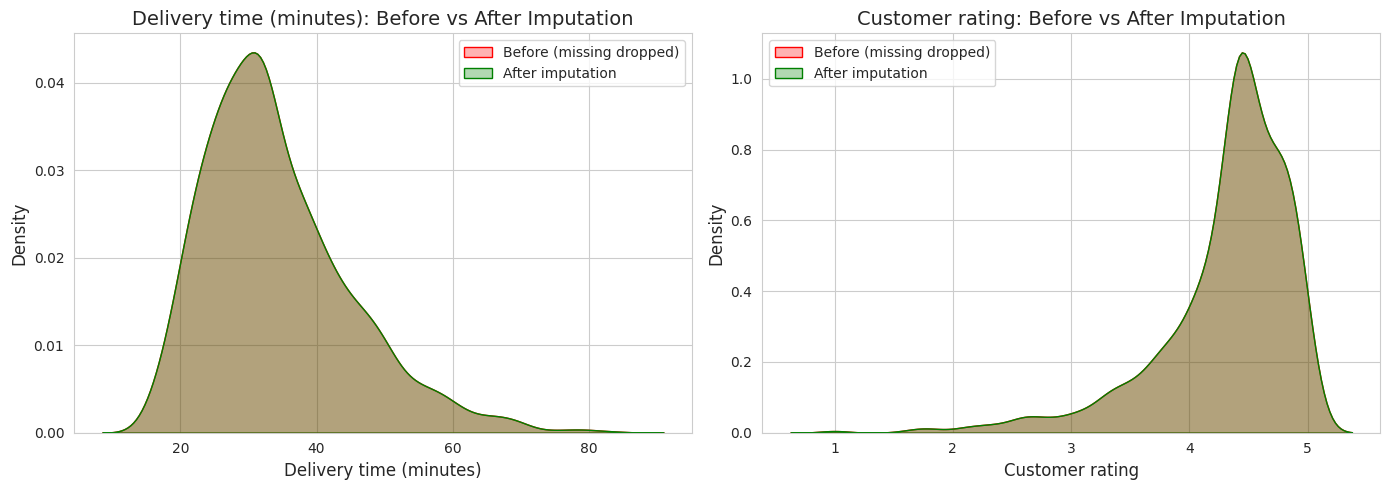

In [121]:
# Chart 5: KDE before vs after imputation
# Overlap means the distribution shape was preserved
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, label in zip(axes,
                          ["delivery_time_min", "customer_rating"],
                          ["Delivery time (minutes)", "Customer rating"]):
    sns.kdeplot(df_before[col].dropna(), ax=ax, label="Before (missing dropped)", color="red", fill=True, alpha=0.3)
    sns.kdeplot(df[col], ax=ax, label="After imputation", color="green", fill=True, alpha=0.3)
    ax.set_title(f"{label}: Before vs After Imputation")
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

In [122]:
# Deliverable 2: save the cleaned dataset
df.to_csv("quickbite_clean.csv", index=False)
print("Saved quickbite_clean.csv with shape:", df.shape)

Saved quickbite_clean.csv with shape: (2000, 18)


In [123]:
# Download the cleaned file to your computer (Colab only)
from google.colab import files
files.download("quickbite_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion of Task 3.1: Missing Value Imputation

**Is missingness random?** No, at least for ratings. Customers who did not rate had a mean delivery time of about 41.5 minutes versus 33.2 for those who did, and 31% of them had a delivery over 45 minutes versus 13%. Unhappy customers are more likely to skip rating.

**Methods and justification**
| Column | Method | Why |
|---|---|---|
| age | Median (32.0) | Robust to unusual ages; mean and median were almost the same, so the choice has little effect |
| delivery_time_min | Median (32.2) | Right-skewed; the mean (34.3) is pulled up by slow deliveries |
| avg_order_value | Median by city tier | Basket size differs by tier (tier 1: 325, tier 3: 289.5), so group-wise fill is more realistic than a global value |
| customer_rating | Median by city tier | Left-skewed, so median is better than mean; group medians were close to the global one (4.4 to 4.5) |
| discount_used_pct | Median | Mean (22.5) and median (22.4) were nearly identical; median is more robust |
| gender | "Unknown" category | Filling with the mode would invent 106 male customers; "Unknown" is more honest |

**Effect on the data:** After imputation there are no missing values. Medians stayed almost unchanged, and the KDE plots overlap closely for delivery time. For customer_rating the peak near 4.4 becomes taller because 13% of values were filled with similar numbers.

**Limitation:** Because missing ratings are linked to slow deliveries, filling them with the typical rating (about 4.4) probably overstates satisfaction for those customers. Ratings should be interpreted with this in mind.

The cleaned dataset was saved as `quickbite_clean.csv`.

---
## Task 3.2: Distribution Shapes with KDE Plots
**Plan:** For each key variable I plot a histogram with a KDE curve, mark the mean, median and mode, compute skewness, and label the shape. Then I show that `avg_order_value` becomes close to normal after a log transform.

**Note on method:** These plots use the observed values only (after outlier removal, before imputation), so the imputed values do not create artificial peaks. The mode of a continuous variable is estimated as the peak of the KDE curve, because exact values rarely repeat.

In [124]:
# Skewness: 0 = symmetric, > 0 = right-skewed (long right tail), < 0 = left-skewed (long left tail)
dist_cols = ["age", "customer_rating", "delivery_time_min",
             "avg_order_value", "annual_spend", "orders_last_12m"]

skew_table = df_before[dist_cols].skew().round(2).to_frame("skewness")
skew_table

,skewness
age,0.13
customer_rating,-1.82
delivery_time_min,1.01
avg_order_value,1.83
annual_spend,15.24
orders_last_12m,5.31


In [125]:
from scipy.stats import gaussian_kde

# This function draws a histogram + KDE and marks the mean, median and mode.
# It returns the statistics so we can collect them into a summary table later.
def plot_dist(series, title, xlabel, clip_q=None):
    s = series.dropna()                              # use observed values only

    mean = s.mean()
    median = s.median()

    # Mode for continuous data = x value where the KDE curve is highest
    kde = gaussian_kde(s)
    grid = np.linspace(s.min(), s.max(), 1000)
    mode = grid[kde(grid).argmax()]

    plt.figure(figsize=(9, 5))
    sns.histplot(s, kde=True, stat="density", bins=40, color="steelblue")

    # Vertical lines for the three measures of centre
    plt.axvline(mean, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean:,.2f}")
    plt.axvline(median, color="green", linestyle="-", linewidth=2, label=f"Median = {median:,.2f}")
    plt.axvline(mode, color="orange", linestyle=":", linewidth=2.5, label=f"Mode (KDE peak) = {mode:,.2f}")

    # For very long tails, cut the x-axis at a quantile so the shape stays readable
    if clip_q is not None:
        plt.xlim(s.min(), s.quantile(clip_q))
        title += f" (x-axis cut at {int(clip_q*100)}th percentile)"

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return {"mean": round(mean, 2), "median": round(median, 2),
            "mode (KDE peak)": round(mode, 2), "skewness": round(s.skew(), 2)}

# Dictionary to collect results for the summary table
dist_summary = {}

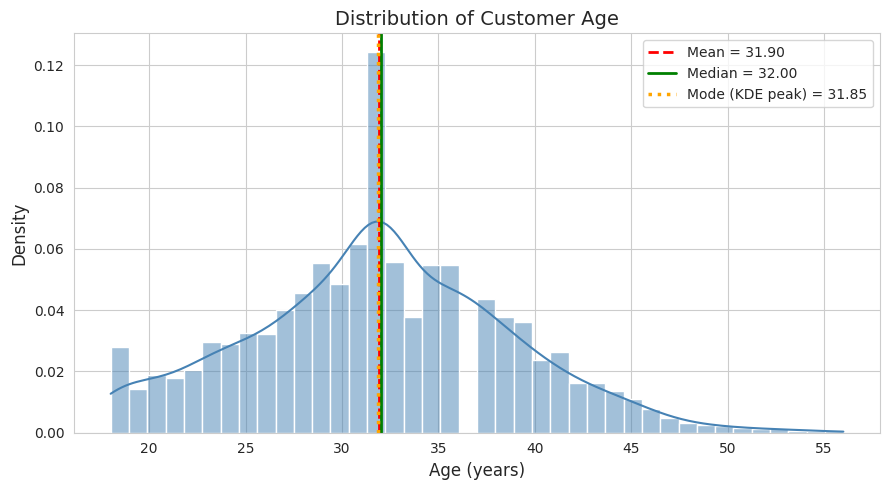

In [126]:
# Chart 6: age (expected: approximately normal)
dist_summary["age"] = plot_dist(df_before["age"], "Distribution of Customer Age", "Age (years)")

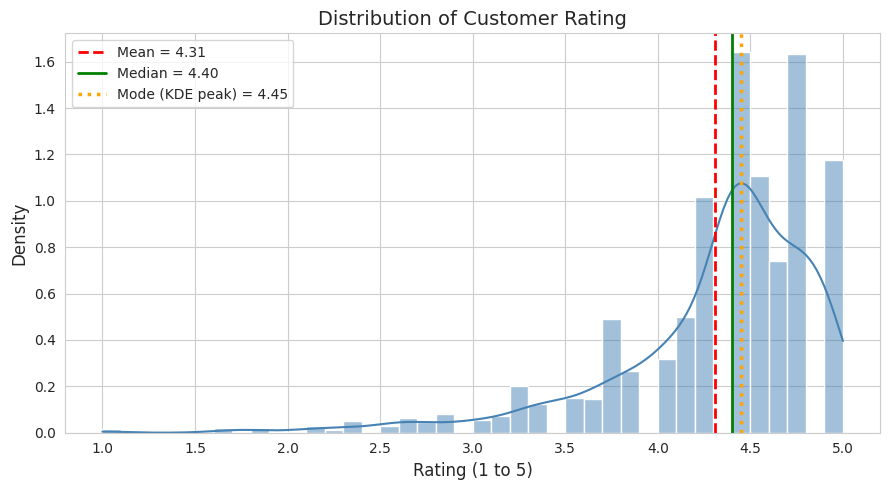

In [127]:
# Chart 7: customer rating (expected: left-skewed)
dist_summary["customer_rating"] = plot_dist(df_before["customer_rating"],
                                            "Distribution of Customer Rating", "Rating (1 to 5)")

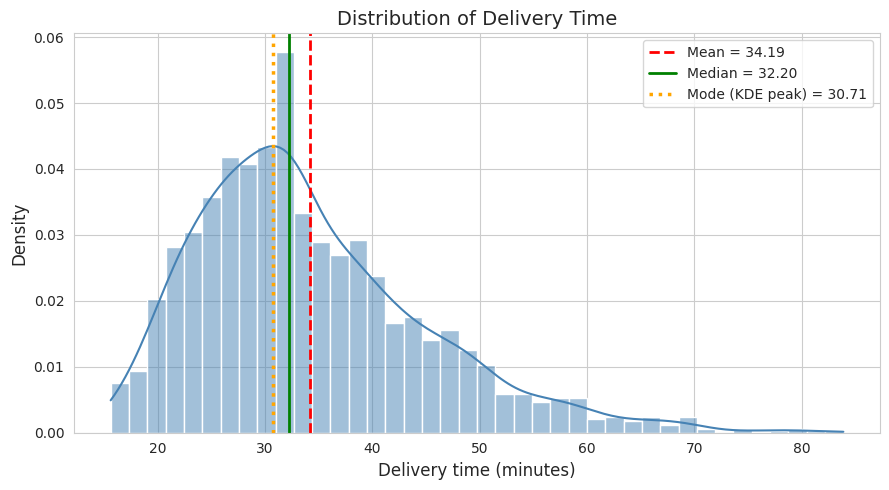

In [128]:
# Chart 8: delivery time (expected: right-skewed)
dist_summary["delivery_time_min"] = plot_dist(df_before["delivery_time_min"],
                                              "Distribution of Delivery Time", "Delivery time (minutes)")

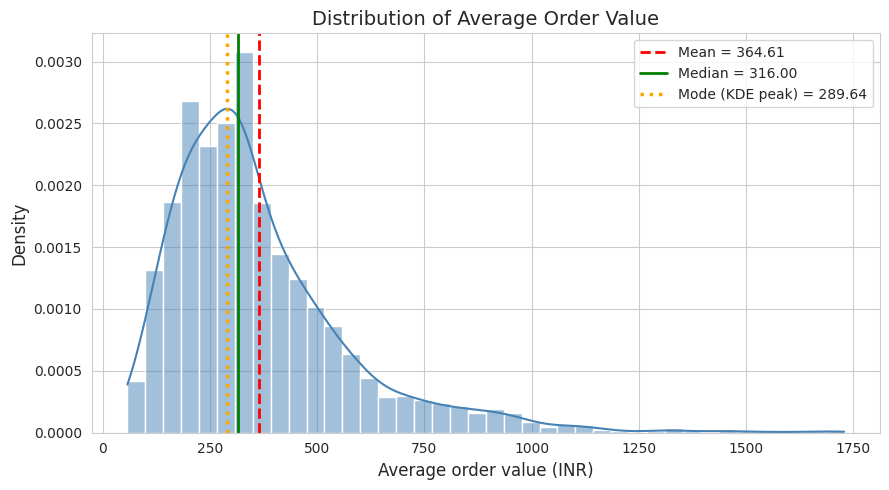

In [129]:
# Chart 9: average order value (expected: right-skewed, log-normal)
dist_summary["avg_order_value"] = plot_dist(df_before["avg_order_value"],
                                            "Distribution of Average Order Value", "Average order value (INR)")

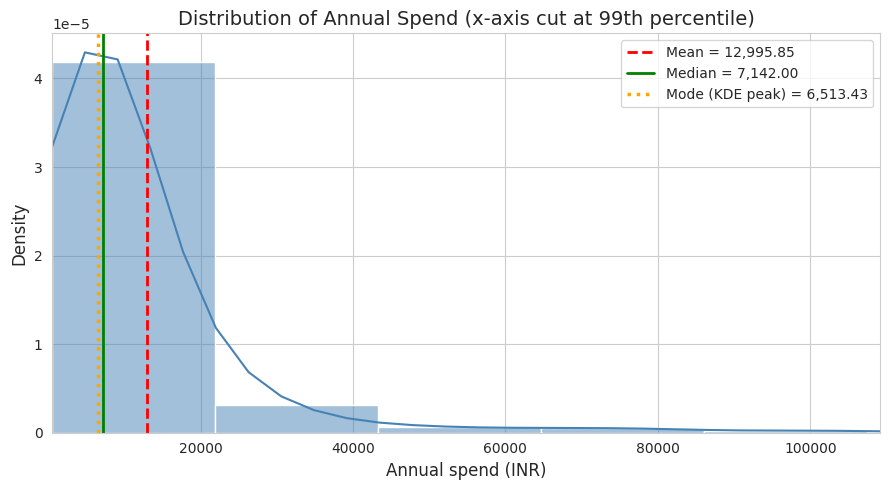

In [130]:
# Chart 10: annual spend (expected: heavy right tail, Pareto-like)
dist_summary["annual_spend"] = plot_dist(df_before["annual_spend"],
                                         "Distribution of Annual Spend", "Annual spend (INR)",
                                         clip_q=0.99)

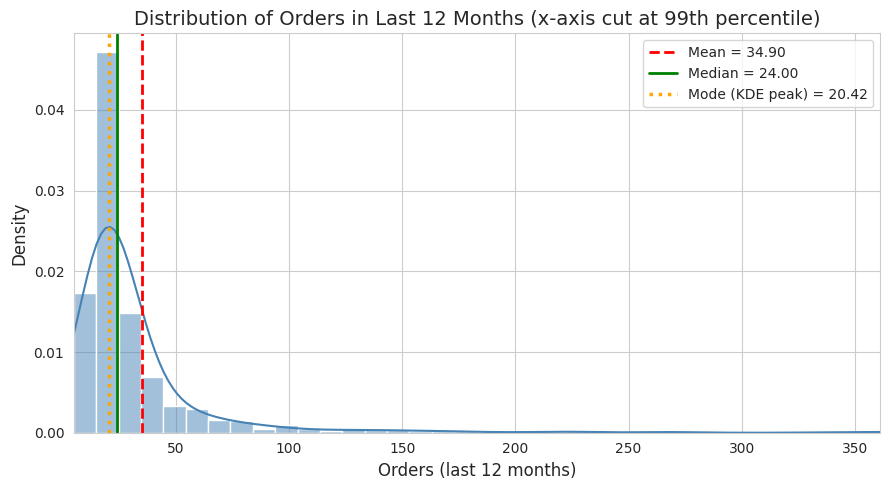

In [131]:
# Chart 11: orders in the last 12 months (expected: heavy right tail)
dist_summary["orders_last_12m"] = plot_dist(df_before["orders_last_12m"],
                                            "Distribution of Orders in Last 12 Months",
                                            "Orders (last 12 months)", clip_q=0.99)

In [132]:
# Combine all results into one table
pd.DataFrame(dist_summary).T

,mean,median,mode (KDE peak),skewness
age,31.90,32.0,31.85,0.13
customer_rating,4.31,4.4,4.45,-1.82
delivery_time_min,34.19,32.2,30.71,1.01
avg_order_value,364.61,316.0,289.64,1.83
annual_spend,12995.85,7142.0,6513.43,15.24
orders_last_12m,34.90,24.0,20.42,5.31


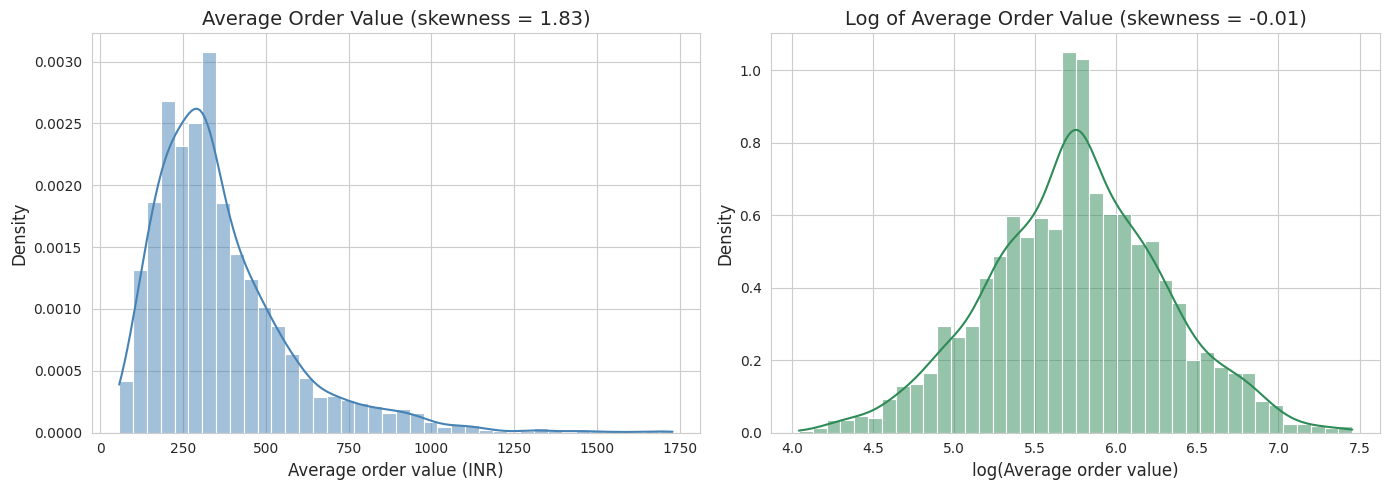

Skewness before log: 1.83
Skewness after log: -0.01


In [133]:
# Chart 12: avg_order_value before and after a log transform
# If a variable is log-normal, its log is approximately normal
aov = df_before["avg_order_value"].dropna()
log_aov = np.log(aov)                         # natural log

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: original values (right-skewed)
sns.histplot(aov, kde=True, stat="density", bins=40, color="steelblue", ax=axes[0])
axes[0].set_title(f"Average Order Value (skewness = {aov.skew():.2f})")
axes[0].set_xlabel("Average order value (INR)")
axes[0].set_ylabel("Density")

# Right: log-transformed values (should look bell-shaped)
sns.histplot(log_aov, kde=True, stat="density", bins=40, color="seagreen", ax=axes[1])
axes[1].set_title(f"Log of Average Order Value (skewness = {log_aov.skew():.2f})")
axes[1].set_xlabel("log(Average order value)")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

print("Skewness before log:", round(aov.skew(), 2))
print("Skewness after log:", round(log_aov.skew(), 2))

### Conclusion of Task 3.2: Distribution Shapes

| Variable | Skewness | Shape |
|---|---|---|
| age | 0.13 | Approximately normal |
| customer_rating | -1.63 | Left-skewed |
| delivery_time_min | 0.96 | Right-skewed |
| avg_order_value | 1.75 | Right-skewed, log-normal (skewness falls to about -0.01 after log) |
| annual_spend | 15.24 | Heavy right tail (Pareto-like) |
| orders_last_12m | 5.31 | Heavy right tail (Pareto-like) |

**Why the order of mean, median and mode flips**
- The **mode** is the peak of the curve, the **median** is the middle value by position, and the **mean** is the only one of the three that is affected by how large the extreme values are.
- In **right-skewed** data (delivery time, order value, spend), a few very large values pull the mean to the right, so the order is **mode < median < mean**. For annual_spend the mean (about 12,996) is almost double the median (7,142).
- In **left-skewed** data (customer rating), a few very low ratings pull the mean to the left, so the order flips to **mean < median < mode** (4.29 < 4.4 < about 4.7).
- In roughly **symmetric** data (age), all three are almost equal.

**Business meaning:** most customers are ordinary users, but a small group of heavy users has very high orders and spend. The "average" customer figure is therefore misleading, and the median describes the typical customer better. Task 7 will measure how concentrated this is.

**Note:** Skewness for delivery time and order value is much lower than in the raw data (about 13.6 and 22) because the 8 recording errors were removed in Task 2. The heavy tails in annual_spend and orders_last_12m were kept because they come from genuine heavy users.

---
## Task 4: Relationships Between Variables
**Plan:** Compute covariance and correlation matrices, visualise the correlations as a heatmap, examine three key relationships with scatter plots, look at trends over signup month with line plots, compare groups with box plots, and then answer which variable is most strongly related to annual_spend.

In [134]:
# Select only numeric columns (text columns like city or membership are excluded)
num_df = df.select_dtypes(include="number")

# Covariance matrix: shows how two variables vary together, but depends on their units
cov_matrix = num_df.cov().round(2)
cov_matrix

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,0.60,0.07,0.12,0.05,1.78,-20.05,-0.00,-0.16,0.38,0.95,-1.022000e+02
age,0.07,46.17,1.05,-0.41,4.15,17.75,-0.02,-15.99,-1.86,2.92,5.424300e+03
tenure_months,0.12,1.05,99.63,-0.19,-0.71,-27.98,0.11,-0.16,-2.99,-7.67,-3.633600e+03
app_sessions_per_month,0.05,-0.41,-0.19,14.28,-1.57,3.06,0.02,-0.93,1.87,14.00,9.728320e+03
delivery_time_min,1.78,4.15,-0.71,-1.57,116.22,-77.30,-0.01,-0.66,-1.31,-3.95,-2.162070e+03
avg_order_value,-20.05,17.75,-27.98,3.06,-77.30,45739.56,0.83,-2.43,-145.79,215.12,1.636312e+06
customer_rating,-0.00,-0.02,0.11,0.02,-0.01,0.83,0.33,-0.02,-0.73,-0.20,4.280000e+00
discount_used_pct,-0.16,-15.99,-0.16,-0.93,-0.66,-2.43,-0.02,85.27,-6.06,5.88,-8.300510e+03
days_since_last_order,0.38,-1.86,-2.99,1.87,-1.31,-145.79,-0.73,-6.06,360.38,8.83,-9.480870e+03
orders_last_12m,0.95,2.92,-7.67,14.00,-3.95,215.12,-0.20,5.88,8.83,2427.95,1.083302e+06


In [135]:
# Correlation matrix: covariance rescaled to a range of -1 to +1, so it is unit-free
corr_matrix = num_df.corr().round(2)
corr_matrix

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,1.00,0.01,0.02,0.02,0.21,-0.12,-0.00,-0.02,0.03,0.02,-0.00
age,0.01,1.00,0.02,-0.02,0.06,0.01,-0.01,-0.25,-0.01,0.01,0.03
tenure_months,0.02,0.02,1.00,-0.01,-0.01,-0.01,0.02,-0.00,-0.02,-0.02,-0.01
app_sessions_per_month,0.02,-0.02,-0.01,1.00,-0.04,0.00,0.01,-0.03,0.03,0.08,0.08
delivery_time_min,0.21,0.06,-0.01,-0.04,1.00,-0.03,-0.00,-0.01,-0.01,-0.01,-0.01
avg_order_value,-0.12,0.01,-0.01,0.00,-0.03,1.00,0.01,-0.00,-0.04,0.02,0.25
customer_rating,-0.00,-0.01,0.02,0.01,-0.00,0.01,1.00,-0.00,-0.07,-0.01,0.00
discount_used_pct,-0.02,-0.25,-0.00,-0.03,-0.01,-0.00,-0.00,1.00,-0.03,0.01,-0.03
days_since_last_order,0.03,-0.01,-0.02,0.03,-0.01,-0.04,-0.07,-0.03,1.00,0.01,-0.02
orders_last_12m,0.02,0.01,-0.02,0.08,-0.01,0.02,-0.01,0.01,0.01,1.00,0.72


In [136]:
# Correlation of every variable with annual_spend, strongest first
corr_with_spend = num_df.corr()["annual_spend"].drop("annual_spend").sort_values(ascending=False).round(3)
corr_with_spend

,annual_spend
orders_last_12m,0.725
avg_order_value,0.252
app_sessions_per_month,0.085
age,0.026
customer_rating,0.000
city_tier,-0.004
delivery_time_min,-0.007
tenure_months,-0.012
days_since_last_order,-0.016
discount_used_pct,-0.030


### Why correlation is easier to interpret than covariance
Covariance depends on the units and scale of the variables, so its size has no fixed meaning. For example, the covariance of annual_spend with avg_order_value (about 1.64 million) is *larger* than with orders_last_12m (about 1.08 million), even though orders is far more strongly related (r = 0.73 vs 0.25). Correlation removes the units and always lies between -1 and +1, so its strength can be compared directly across any pair of variables.

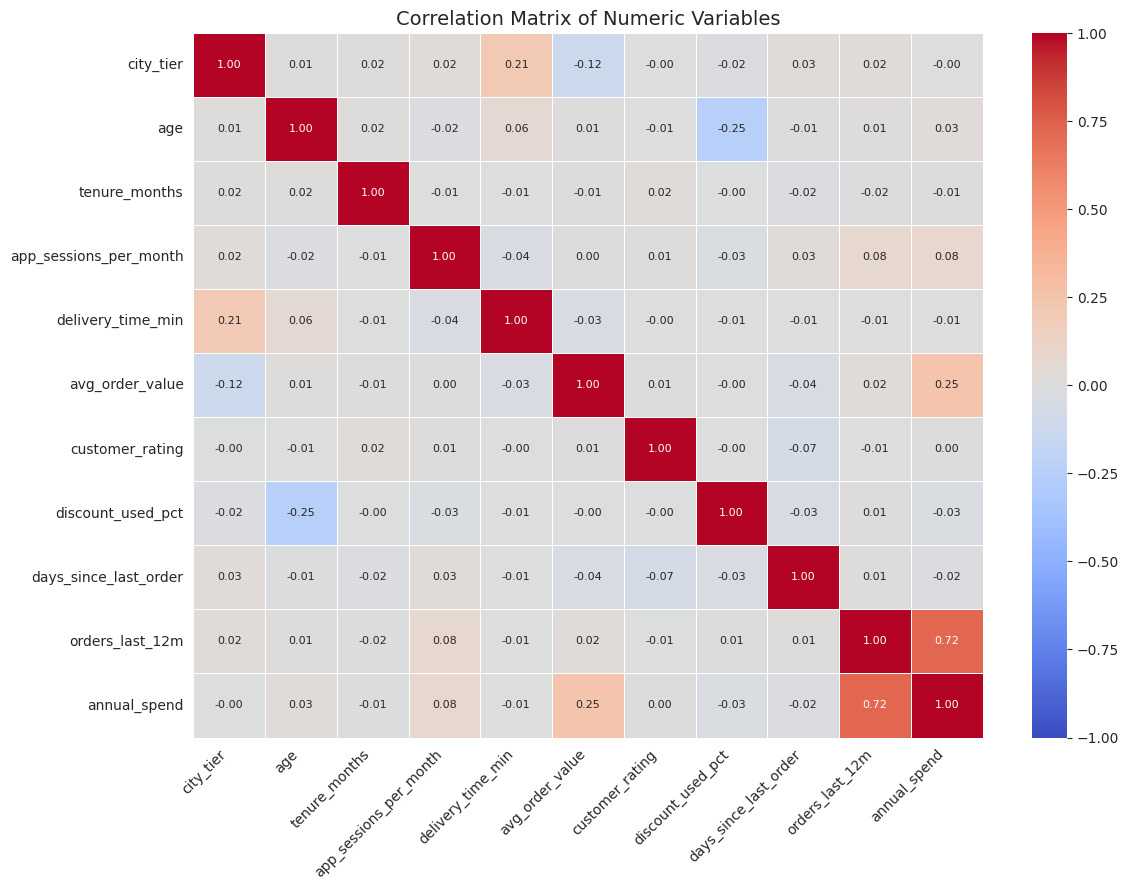

In [137]:
# Chart 13: annotated correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={"size": 8})
plt.title("Correlation Matrix of Numeric Variables")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

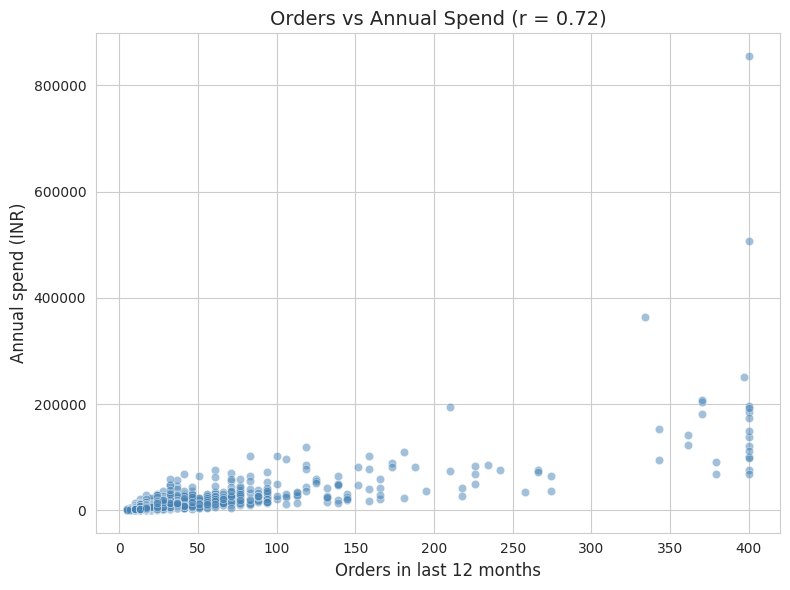

In [138]:
# Chart 14: orders_last_12m vs annual_spend
r = df["orders_last_12m"].corr(df["annual_spend"])

plt.figure(figsize=(8, 6))
sns.scatterplot(x="orders_last_12m", y="annual_spend", data=df, alpha=0.5, color="steelblue")
plt.title(f"Orders vs Annual Spend (r = {r:.2f})")
plt.xlabel("Orders in last 12 months")
plt.ylabel("Annual spend (INR)")
plt.tight_layout()
plt.show()

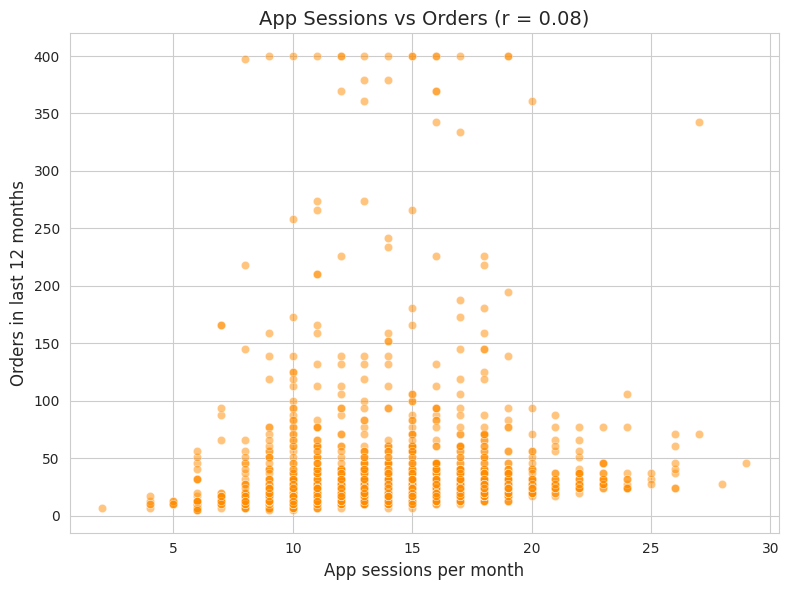

In [139]:
# Chart 15: app_sessions_per_month vs orders_last_12m
r = df["app_sessions_per_month"].corr(df["orders_last_12m"])

plt.figure(figsize=(8, 6))
sns.scatterplot(x="app_sessions_per_month", y="orders_last_12m", data=df, alpha=0.5, color="darkorange")
plt.title(f"App Sessions vs Orders (r = {r:.2f})")
plt.xlabel("App sessions per month")
plt.ylabel("Orders in last 12 months")
plt.tight_layout()
plt.show()

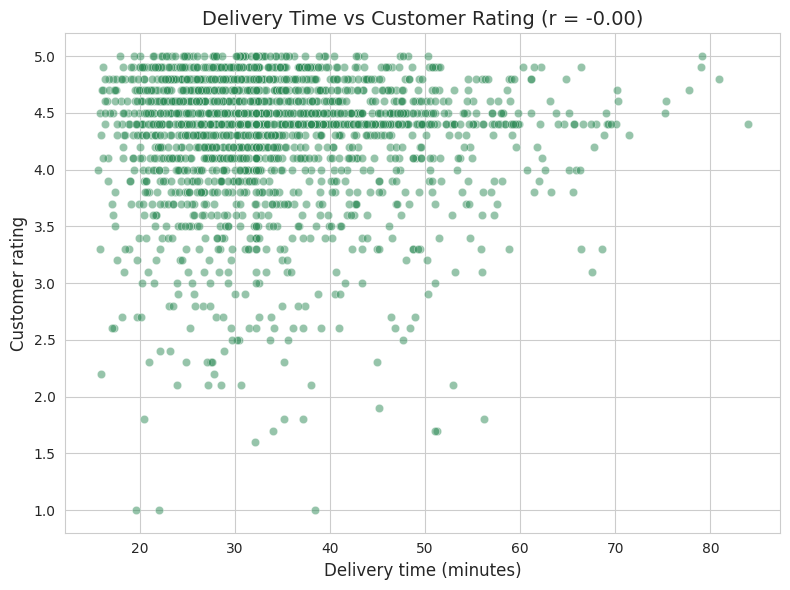

In [140]:
# Chart 16: delivery_time_min vs customer_rating
r = df["delivery_time_min"].corr(df["customer_rating"])

plt.figure(figsize=(8, 6))
sns.scatterplot(x="delivery_time_min", y="customer_rating", data=df, alpha=0.5, color="seagreen")
plt.title(f"Delivery Time vs Customer Rating (r = {r:.2f})")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.tight_layout()
plt.show()

In [141]:
# Group customers by signup month (resample "MS" = month start)
monthly = df.set_index("signup_date").resample("MS").agg(
    new_signups=("customer_id", "count"),
    avg_delivery=("delivery_time_min", "mean"))

# The data ends on 5 Nov 2025, so the last month is incomplete (only 7 signups).
# Drop it so it doesn't look like a sudden fall.
monthly = monthly.iloc[:-1]
print("Months plotted:", len(monthly))

Months plotted: 34


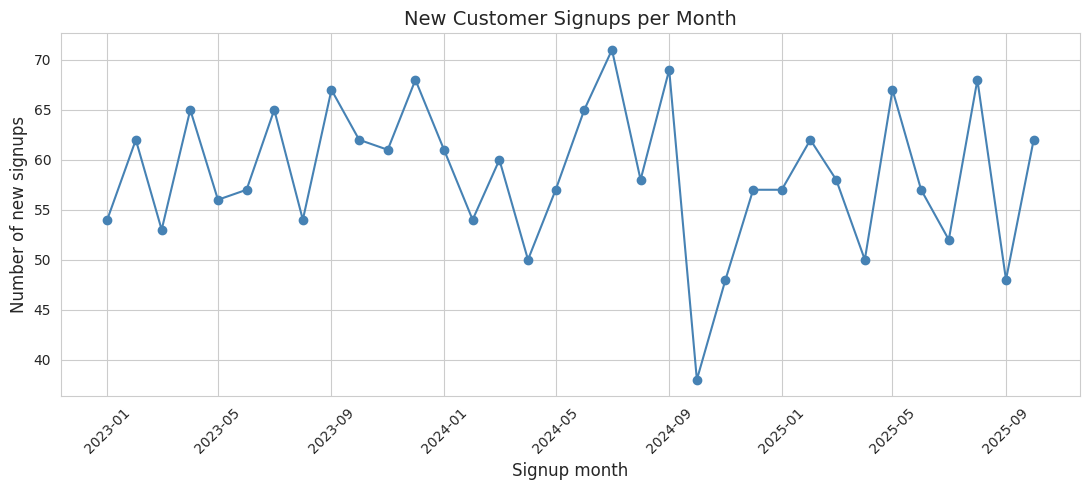

In [142]:
# Chart 17: new signups per month
plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly["new_signups"], marker="o", color="steelblue")
plt.title("New Customer Signups per Month")
plt.xlabel("Signup month")
plt.ylabel("Number of new signups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

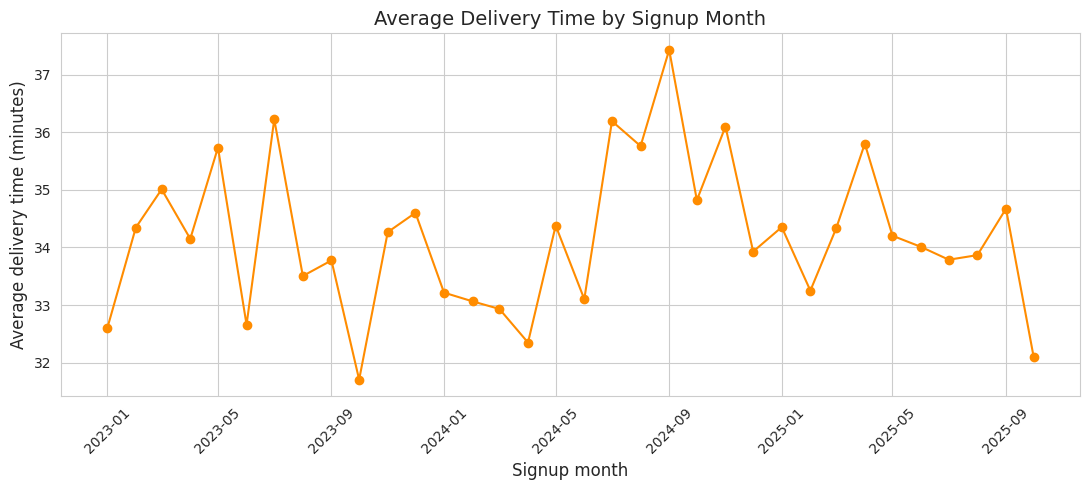

In [143]:
# Chart 18: average delivery time by signup month
plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly["avg_delivery"], marker="o", color="darkorange")
plt.title("Average Delivery Time by Signup Month")
plt.xlabel("Signup month")
plt.ylabel("Average delivery time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_652/1631929002.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="membership", y="annual_spend", data=df,


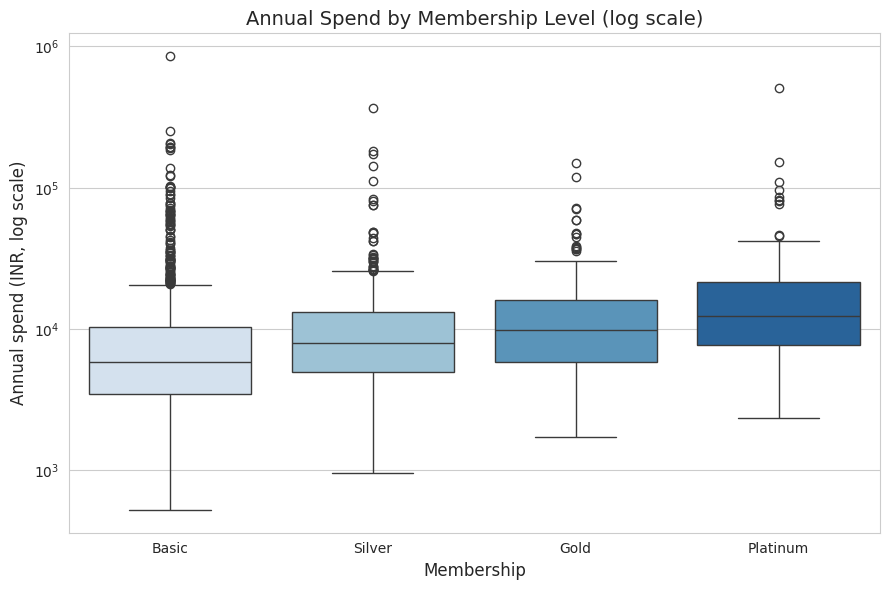

,annual_spend
membership,
Basic,5875.0
Silver,7993.0
Gold,9802.0
Platinum,12362.5


In [144]:
# Chart 19: annual spend by membership level
# Log scale on the y-axis because a few very large spenders would flatten the boxes
plt.figure(figsize=(9, 6))
sns.boxplot(x="membership", y="annual_spend", data=df,
            order=["Basic", "Silver", "Gold", "Platinum"], palette="Blues")
plt.yscale("log")
plt.title("Annual Spend by Membership Level (log scale)")
plt.xlabel("Membership")
plt.ylabel("Annual spend (INR, log scale)")
plt.tight_layout()
plt.show()

# Median spend per membership level
df.groupby("membership")["annual_spend"].median().reindex(["Basic", "Silver", "Gold", "Platinum"])

/tmp/ipykernel_652/1377000257.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="city_tier", y="delivery_time_min", data=df, palette="Oranges")


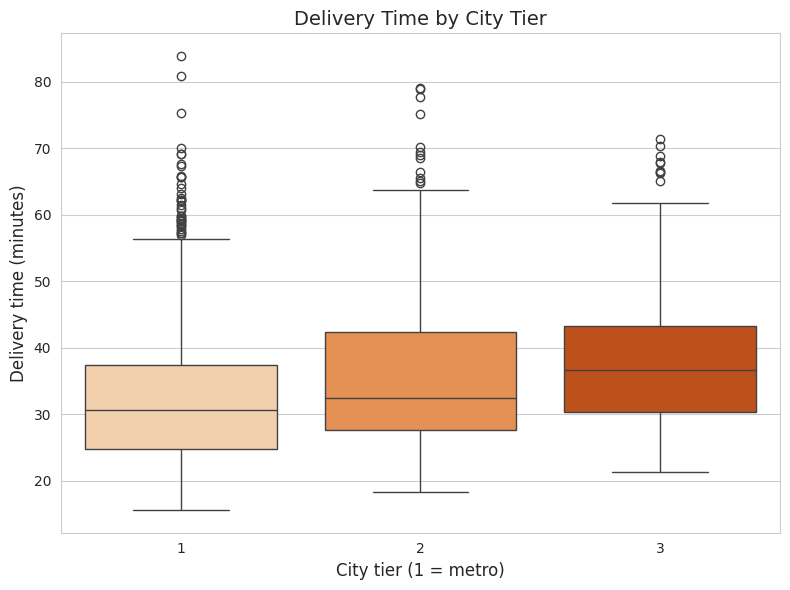

,delivery_time_min
city_tier,
1,30.6
2,32.5
3,36.6


In [145]:
# Chart 20: delivery time by city tier
plt.figure(figsize=(8, 6))
sns.boxplot(x="city_tier", y="delivery_time_min", data=df, palette="Oranges")
plt.title("Delivery Time by City Tier")
plt.xlabel("City tier (1 = metro)")
plt.ylabel("Delivery time (minutes)")
plt.tight_layout()
plt.show()

# Median delivery time per tier
df.groupby("city_tier")["delivery_time_min"].median().round(1)

### Conclusion of Task 4: Relationships

**Strongest relationship with annual_spend:** `orders_last_12m` (r = 0.72). The next is `avg_order_value` (r = 0.25), followed by `app_sessions_per_month` (r = 0.08). All other variables, including delivery time, rating, age, tenure and discount use, are close to zero.

**Other findings**
- App sessions and orders are only weakly related (r = 0.08).
- Delivery time and rating show almost no linear relationship (r ≈ 0), though imputed ratings may hide a real effect.
- Spend rises with membership level (median 5,875 for Basic to 12,362 for Platinum).
- Delivery is slower in lower-tier cities (median 30.6 min in Tier 1 vs 36.6 in Tier 3).
- Signups are steady at roughly 55-60 per month, and delivery time shows no trend by signup month. The last month (Nov 2025) was excluded because the data covers only its first 5 days.

**Does correlation prove causation? No.** Correlation only shows that two variables move together. Orders and spend are linked partly by definition, because spending is made up of orders, so the relationship is strong but not very surprising. Membership and spend are also linked, but we cannot tell whether membership causes higher spend or whether heavy spenders are simply upgraded to higher tiers. Proving cause would need an experiment or a more careful study design.

**Business takeaway:** to grow revenue per customer, order *frequency* matters most, followed by basket size.

---
## Task 5: Encoding Categorical Variables
**Plan:** Convert text categories into numbers using three techniques, each chosen to match the type of variable:
- **Label (ordinal) encoding** for `membership`, because its order is meaningful (Basic < Silver < Gold < Platinum).
- **One-hot encoding** for `device_type` and `acquisition_channel`, because these categories have no order.
- **Target encoding** for `city`, replacing each city with its mean annual_spend.

The encoded columns are stored in a copy (`df_enc`) so the cleaned dataset stays unchanged.

In [146]:
# Work on a copy so the cleaned df is not altered
df_enc = df.copy()

# Label (ordinal) encoding: the numbers follow the real order of membership levels
membership_map = {"Basic": 0, "Silver": 1, "Gold": 2, "Platinum": 3}
df_enc["membership_encoded"] = df_enc["membership"].map(membership_map)

# Check that the mapping worked and nothing became missing
print("Missing after mapping:", df_enc["membership_encoded"].isna().sum())
df_enc["membership_encoded"].value_counts().sort_index()

Missing after mapping: 0


,count
membership_encoded,
0,1179
1,436
2,237
3,148


In [147]:
# One-hot encoding: one 0/1 column per category (dtype=int shows 0/1 instead of True/False)
onehot_full = pd.get_dummies(df_enc[["device_type", "acquisition_channel"]], dtype=int)
print("Without drop_first:", onehot_full.shape[1], "columns")
print(onehot_full.columns.tolist(), "\n")

# With drop_first=True: removes one category per variable to avoid the dummy variable trap
onehot = pd.get_dummies(df_enc[["device_type", "acquisition_channel"]], drop_first=True, dtype=int)
print("With drop_first:", onehot.shape[1], "columns")
print(onehot.columns.tolist())

# Add the dummy columns to the encoded DataFrame
df_enc = pd.concat([df_enc, onehot], axis=1)

Without drop_first: 8 columns
['device_type_Android', 'device_type_Web', 'device_type_iOS', 'acquisition_channel_Influencer', 'acquisition_channel_Organic', 'acquisition_channel_Paid Social', 'acquisition_channel_Referral', 'acquisition_channel_Search Ads'] 

With drop_first: 6 columns
['device_type_Web', 'device_type_iOS', 'acquisition_channel_Organic', 'acquisition_channel_Paid Social', 'acquisition_channel_Referral', 'acquisition_channel_Search Ads']


In [148]:
# Dummy variable trap: if we keep ALL device dummies, they always add up to 1,
# so any one column can be predicted exactly from the others (perfect redundancy).
device_cols = [c for c in onehot_full.columns if c.startswith("device_type_")]
print("Row sums of all device dummies (unique values):", onehot_full[device_cols].sum(axis=1).unique())

Row sums of all device dummies (unique values): [1]


In [149]:
# Target encoding: replace each city with the mean annual_spend of that city
city_mean = df_enc.groupby("city")["annual_spend"].mean()
df_enc["city_target_encoded"] = df_enc["city"].map(city_mean)

# For contrast, alphabetical label encoding of city (arbitrary numbers)
df_enc["city_label_alpha"] = df_enc["city"].astype("category").cat.codes

# Show the mapping city -> both encodings, sorted by target encoding
city_table = (df_enc.groupby("city")[["city_label_alpha", "city_target_encoded"]]
              .first().round(0).sort_values("city_target_encoded", ascending=False))
city_table

,city_label_alpha,city_target_encoded
city,,
Hyderabad,2,18300.0
Kochi,5,15740.0
Nagpur,8,15516.0
Lucknow,6,13940.0
Delhi,1,12152.0
Mumbai,7,12021.0
Bengaluru,0,12004.0
Pune,9,10929.0
Indore,3,10733.0


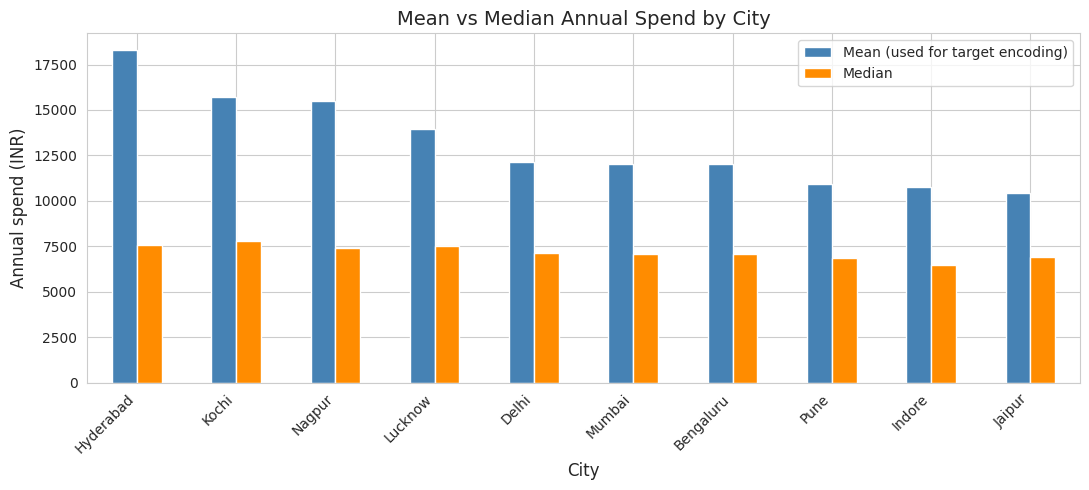

In [150]:
# Chart 21: mean vs median annual spend by city
# Shows that the target-encoded mean is pulled up by a few very large spenders
city_stats = df_enc.groupby("city")["annual_spend"].agg(["mean", "median"]).sort_values("mean", ascending=False)

city_stats.plot(kind="bar", figsize=(11, 5), color=["steelblue", "darkorange"])
plt.title("Mean vs Median Annual Spend by City")
plt.xlabel("City")
plt.ylabel("Annual spend (INR)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Mean (used for target encoding)", "Median"])
plt.tight_layout()
plt.show()

In [151]:
# Show original and encoded columns side by side for the first 10 customers
side_by_side = df_enc[["membership", "membership_encoded",
                       "city", "city_label_alpha", "city_target_encoded",
                       "device_type", "device_type_Web", "device_type_iOS",
                       "acquisition_channel", "acquisition_channel_Organic",
                       "acquisition_channel_Paid Social"]].head(10)
side_by_side

,membership,membership_encoded,city,city_label_alpha,city_target_encoded,device_type,device_type_Web,device_type_iOS,acquisition_channel,acquisition_channel_Organic,acquisition_channel_Paid Social
0,Basic,0,Lucknow,6,13939.898649,Android,0,0,Referral,0,0
1,Basic,0,Bengaluru,0,12004.006803,iOS,0,1,Influencer,0,0
2,Basic,0,Indore,3,10732.646259,iOS,0,1,Referral,0,0
3,Basic,0,Jaipur,4,10410.643357,Android,0,0,Paid Social,0,1
4,Basic,0,Mumbai,7,12020.796875,Android,0,0,Search Ads,0,0
5,Basic,0,Kochi,5,15739.561905,Android,0,0,Paid Social,0,1
6,Silver,1,Lucknow,6,13939.898649,iOS,0,1,Search Ads,0,0
7,Basic,0,Lucknow,6,13939.898649,iOS,0,1,Organic,1,0
8,Basic,0,Mumbai,7,12020.796875,iOS,0,1,Organic,1,0
9,Silver,1,Bengaluru,0,12004.006803,Android,0,0,Paid Social,0,1


### Conclusion of Task 5: Encoding

| Variable | Technique | Reason |
|---|---|---|
| membership | Label (ordinal): Basic=0, Silver=1, Gold=2, Platinum=3 | The order is real, and median spend rises with each level (Task 4) |
| device_type, acquisition_channel | One-hot with `drop_first=True` (8 columns reduced to 6) | The categories have no order |
| city | Target encoding (mean annual_spend) | 10 categories with no natural order |

**The dummy variable trap:** If all dummy columns are kept, they always add up to 1, so any one column can be calculated from the others (perfect redundancy). That causes problems for methods such as regression. Dropping one category per variable (`drop_first=True`) removes the redundancy, and the dropped category (Android, Influencer) becomes the baseline.

**Why alphabetical label encoding of city is misleading:** It gives Bengaluru=0, Delhi=1, ... Pune=9. These numbers imply an order and distances that do not exist, for example that Pune is "greater than" Mumbai, or that Delhi is exactly one step above Bengaluru. A numeric method would treat those gaps as meaningful.

**Why one-hot on cities is wide:** It needs one column per city (10, or 9 with `drop_first`). That is manageable here, but with hundreds of cities the data would become very wide and mostly zeros.

**Risk of target encoding:**
- **Leakage:** The new feature is built from the target (annual_spend). If it is later used to predict the same target, each customer's own spend has already influenced their feature, which makes results look better than they really are. The usual fix is to compute the means only on training data, or use cross-validation.
- **Sensitivity to outliers:** Means are pulled by large spenders. Hyderabad has the highest mean (18,300), but its median is similar to the other cities, so the encoding partly reflects a few heavy users (Chart 21).
- **Small groups:** Cities with few customers give unstable averages.

No model is built in this project, so the leakage is only a concern for the future.

---
## Task 6: Central Tendency and Percentiles
**Plan:** Compute mean, median and mode for age, orders_last_12m and annual_spend (mode only for membership), explain why mean is much larger than median for annual_spend, compute percentiles for delivery_time_min and annual_spend, draw box plots with annotated quartiles, and answer the P90 delivery-time question.

Modes are calculated on observed values (before imputation), so the imputed fill values do not appear as artificial "most common" values.

In [152]:
# Mean, median and mode for age, orders and annual spend
# Using df_before (observed values only, outliers removed, no imputation)
tend = pd.DataFrame({
    "mean": df_before[["age", "orders_last_12m", "annual_spend"]].mean().round(2),
    "median": df_before[["age", "orders_last_12m", "annual_spend"]].median(),
    "mode": [df_before["age"].mode()[0],
             df_before["orders_last_12m"].mode()[0],
             np.nan]                                   # annual_spend mode handled below
})
tend

,mean,median,mode
age,31.90,32.0,32.0
orders_last_12m,34.90,24.0,17.0
annual_spend,12995.85,7142.0,NaN


In [153]:
# annual_spend is almost continuous: check how often the most common values repeat
print("Most frequent annual_spend values:")
print(df_before["annual_spend"].value_counts().head(3), "\n")

# Raw mode is meaningless here (each value appears only about 3 times),
# so use the KDE peak calculated in Task 3 as the estimated mode
spend_mode = dist_summary["annual_spend"]["mode (KDE peak)"]
tend.loc["annual_spend", "mode"] = spend_mode
print("Estimated mode of annual_spend (KDE peak):", spend_mode, "\n")

# membership is categorical, so only the mode is meaningful
print("Mode of membership:", df["membership"].mode()[0])
print(df["membership"].value_counts())

Most frequent annual_spend values:
annual_spend
4741.0    3
2916.0    3
6275.0    3
Name: count, dtype: int64 

Estimated mode of annual_spend (KDE peak): 6513.43 

Mode of membership: Basic
membership
Basic       1179
Silver       436
Gold         237
Platinum     148
Name: count, dtype: int64


In [154]:
# Compare mean and median of annual_spend
mean_spend = df["annual_spend"].mean()
median_spend = df["annual_spend"].median()

print(f"Mean annual spend:   {mean_spend:,.0f}")
print(f"Median annual spend: {median_spend:,.0f}")
print(f"Mean / median ratio: {mean_spend / median_spend:.2f}")

# Share of customers who spend more than the mean
above_mean = (df["annual_spend"] > mean_spend).mean() * 100
print(f"Customers spending more than the mean: {above_mean:.1f}%")

# Revenue share of the 20 biggest customers (the top 1%)
top20 = df["annual_spend"].sort_values(ascending=False).head(20).sum()
print(f"Revenue share of the top 20 customers (1%): {top20 / df['annual_spend'].sum() * 100:.1f}%")

Mean annual spend:   12,996
Median annual spend: 7,142
Mean / median ratio: 1.82
Customers spending more than the mean: 24.4%
Revenue share of the top 20 customers (1%): 17.6%


In [155]:
# Percentiles: the value below which that share of customers fall
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
labels = ["P10", "P25", "P50", "P75", "P90", "P95", "P99"]

pct_table = pd.DataFrame({
    "delivery_time_min": df["delivery_time_min"].quantile(percentiles).values,
    "annual_spend": df["annual_spend"].quantile(percentiles).values
}, index=labels).round(1)
pct_table

,delivery_time_min,annual_spend
P10,22.1,2508.6
P25,26.5,4085.8
P50,32.2,7142.0
P75,40.0,12781.2
P90,48.9,22453.7
P95,55.0,35355.2
P99,67.4,109149.8


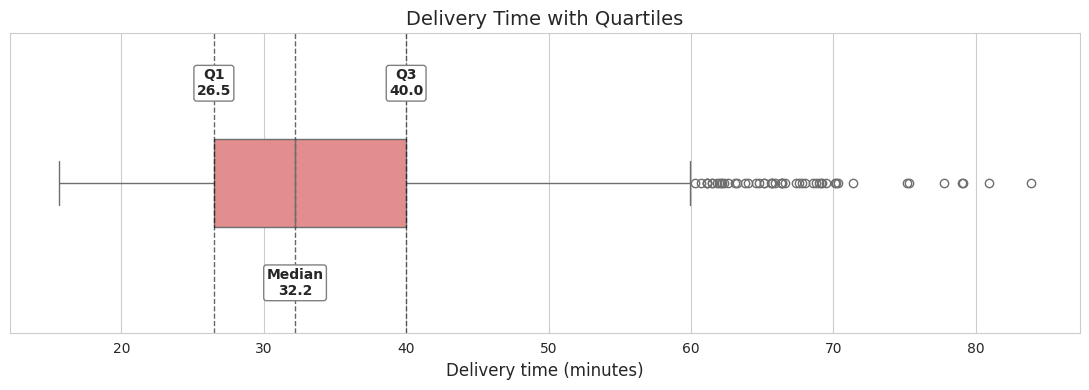

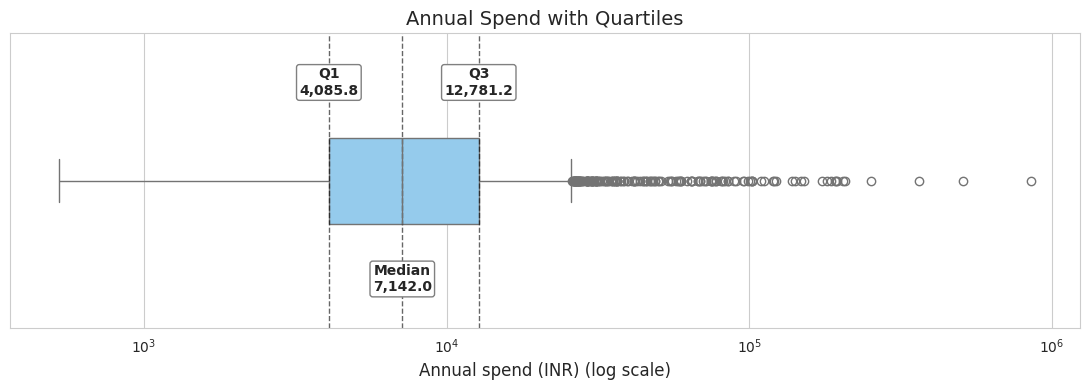

In [156]:
# Function: horizontal box plot with Q1, median and Q3 written on the chart
def annotated_boxplot(series, title, xlabel, color, log=False):
    q1, q2, q3 = series.quantile([0.25, 0.5, 0.75])

    plt.figure(figsize=(11, 4))
    sns.boxplot(x=series, color=color, width=0.35)

    # Mark each quartile with a dashed line and a text label
    # Q1 and Q3 are labelled above the box, the median below it, so labels do not overlap
    for value, name, y in [(q1, "Q1", 0.40), (q2, "Median", -0.40), (q3, "Q3", 0.40)]:
        plt.axvline(value, color="black", linestyle="--", linewidth=1, alpha=0.6)
        plt.text(value, y, f"{name}\n{value:,.1f}", ha="center", va="center",
                 fontsize=10, fontweight="bold",
                 bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.2"))

    if log:
        plt.xscale("log")
        xlabel += " (log scale)"

    plt.ylim(-0.6, 0.6)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

# Chart 22: delivery time
annotated_boxplot(df["delivery_time_min"], "Delivery Time with Quartiles",
                  "Delivery time (minutes)", "lightcoral")

# Chart 23: annual spend (log scale, because of the very long right tail)
annotated_boxplot(df["annual_spend"], "Annual Spend with Quartiles",
                  "Annual spend (INR)", "lightskyblue", log=True)

In [157]:
# Business question: what delivery time do 90% of customers experience or better?
p90 = df["delivery_time_min"].quantile(0.90)
print(f"P90 delivery time: {p90:.1f} minutes")
print(f"Share of customers with delivery <= 45 min: {(df['delivery_time_min'] <= 45).mean() * 100:.1f}%")

P90 delivery time: 48.9 minutes
Share of customers with delivery <= 45 min: 84.4%


### Conclusion of Task 6: Central Tendency and Percentiles

| Variable | Mean | Median | Mode |
|---|---|---|---|
| age | 31.89 | 32.0 | 31 |
| orders_last_12m | 34.90 | 24 | 17 |
| annual_spend | 12,996 | 7,142 | about 6,500 (KDE peak; no true repeated value) |
| membership | n/a | n/a | Basic (1,179 customers) |

**Why mean is much bigger than median for annual_spend:** A small number of very high spenders pull the mean up, while the median depends only on the middle customer. The mean (12,996) is about 1.8 times the median (7,142), and only 24.4% of customers spend more than the mean.

**What it means for the business:**
- The "average customer spends about 13,000 INR" figure overstates a typical customer. The median (about 7,100 INR) is a better description of the normal customer.
- Revenue depends heavily on a small group of heavy users. The top 20 customers (1%) alone generate 17.6% of revenue, and the 99th percentile (about 109,000 INR) is about 15 times the median.
- Losing a few top customers would hurt revenue much more than losing many typical ones, so retention of high-value customers deserves special attention.

**Delivery performance (P90):** 90% of customers receive their order in **about 49 minutes or less**, and 84% receive it within 45 minutes. The median delivery is 32.2 minutes, but the slowest 10% wait from about 49 minutes to over an hour, which is where the poor ratings and missing feedback tend to come from.

**Note on accuracy:** Percentiles were calculated on the cleaned dataset, where missing delivery times were filled with the median. Using observed values only gives nearly the same result (P90 about 49.4 minutes).

---
## Task 7: Pareto Distribution and the 80/20 Rule
**Plan:** Sort customers from highest to lowest annual_spend, compute the cumulative share of revenue, find what percentage of customers generate 50% and 80% of revenue, compare the top 20% share with the classic 80/20 rule, and compare annual_spend on a normal scale versus a log scale.

All 2,000 customers are used, including the very large spenders, because they are genuine high-value customers (see Task 2).

In [158]:
# Sort customers from the biggest spender to the smallest
sorted_spend = df["annual_spend"].sort_values(ascending=False).reset_index(drop=True)

n = len(sorted_spend)                     # number of customers (2000)
total_revenue = sorted_spend.sum()        # total annual spend of all customers

# Cumulative revenue share (%) as we move down the ranked list
cum_share = sorted_spend.cumsum() / total_revenue * 100

# Percentage of customers covered at each rank (1/2000 = 0.05%, ... 2000/2000 = 100%)
customer_pct = np.arange(1, n + 1) / n * 100

# Put everything in one table
pareto = pd.DataFrame({"customer_pct": customer_pct,
                       "annual_spend": sorted_spend,
                       "cum_revenue_pct": cum_share})

print(f"Total annual revenue: {total_revenue:,.0f} INR")
pareto.head()

Total annual revenue: 25,991,704 INR


,customer_pct,annual_spend,cum_revenue_pct
0,0.05,855443.0,3.291216
1,0.10,507406.0,5.243400
2,0.15,364740.0,6.646694
3,0.20,251922.0,7.615934
4,0.25,207118.0,8.412796


In [159]:
# Smallest number of customers needed to reach 50% and 80% of revenue
n50 = np.argmax((cum_share >= 50).values) + 1
n80 = np.argmax((cum_share >= 80).values) + 1

print(f"50% of revenue comes from {n50} customers = {n50 / n * 100:.1f}% of customers")
print(f"80% of revenue comes from {n80} customers = {n80 / n * 100:.1f}% of customers")

# Revenue share of the top X% of customers
rows = []
for p in [1, 5, 10, 20, 50]:
    k = int(n * p / 100)
    rows.append({"Top % of customers": p, "Customers": k,
                 "Share of revenue (%)": round(cum_share.iloc[k - 1], 2)})
top_share = pd.DataFrame(rows)
print()
print(top_share.to_string(index=False))

# Spend level that separates the top 20% from the rest
top20_cut = sorted_spend.iloc[int(n * 0.2) - 1]
print(f"\nTop 20% of customers each spend at least {top20_cut:,.0f} INR")

# Robustness check: is the result driven by the single largest customer?
rest = sorted_spend.iloc[1:]
share_without_max = rest.cumsum().iloc[int(n * 0.2) - 1] / rest.sum() * 100
print(f"Top 20% share after removing the largest customer: {share_without_max:.1f}%")

50% of revenue comes from 238 customers = 11.9% of customers
80% of revenue comes from 862 customers = 43.1% of customers

 Top % of customers  Customers  Share of revenue (%)
                  1         20                 17.58
                  5        100                 36.34
                 10        200                 46.94
                 20        400                 60.61
                 50       1000                 84.06

Top 20% of customers each spend at least 14,589 INR
Top 20% share after removing the largest customer: 59.3%


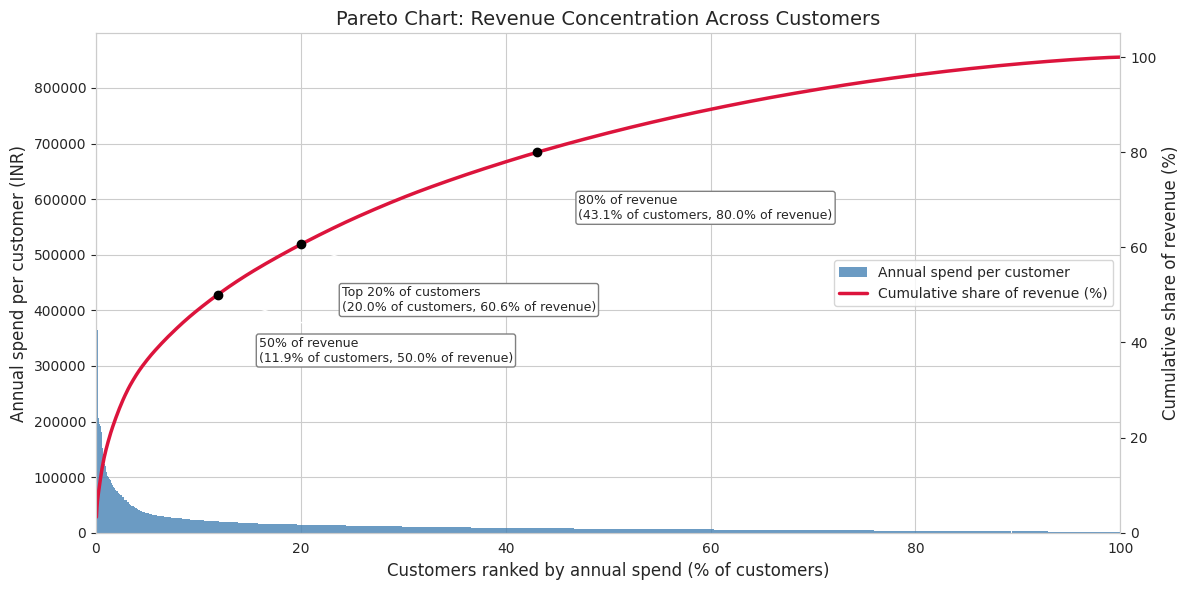

In [160]:
# Chart 24: Pareto chart
# Bars = spend of each customer (ranked), line = cumulative share of revenue
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bars: each customer's annual spend
ax1.bar(pareto["customer_pct"], pareto["annual_spend"], width=100 / n,
        color="steelblue", alpha=0.8, linewidth=0, label="Annual spend per customer")
ax1.set_xlabel("Customers ranked by annual spend (% of customers)")
ax1.set_ylabel("Annual spend per customer (INR)")
ax1.set_xlim(0, 100)

# Line: cumulative revenue share on a second y-axis
ax2 = ax1.twinx()
ax2.plot(pareto["customer_pct"], pareto["cum_revenue_pct"], color="crimson",
         linewidth=2.5, label="Cumulative share of revenue (%)")
ax2.set_ylabel("Cumulative share of revenue (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)                                   # avoid a double grid

# Mark the key points: 50% of revenue, 80% of revenue, and the top 20% of customers
top20_share = cum_share.iloc[int(n * 0.2) - 1]
points = [(n50 / n * 100, 50, "50% of revenue"),
          (n80 / n * 100, 80, "80% of revenue"),
          (20, top20_share, "Top 20% of customers")]
for x, y, label in points:
    ax2.scatter(x, y, color="black", zorder=5)
    ax2.annotate(f"{label}\n({x:.1f}% of customers, {y:.1f}% of revenue)",
                 xy=(x, y), xytext=(x + 4, y - 14),
                 arrowprops=dict(arrowstyle="->"), fontsize=9,
                 bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.2"))

# One combined legend for both axes
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right")

plt.title("Pareto Chart: Revenue Concentration Across Customers")
plt.tight_layout()
plt.show()

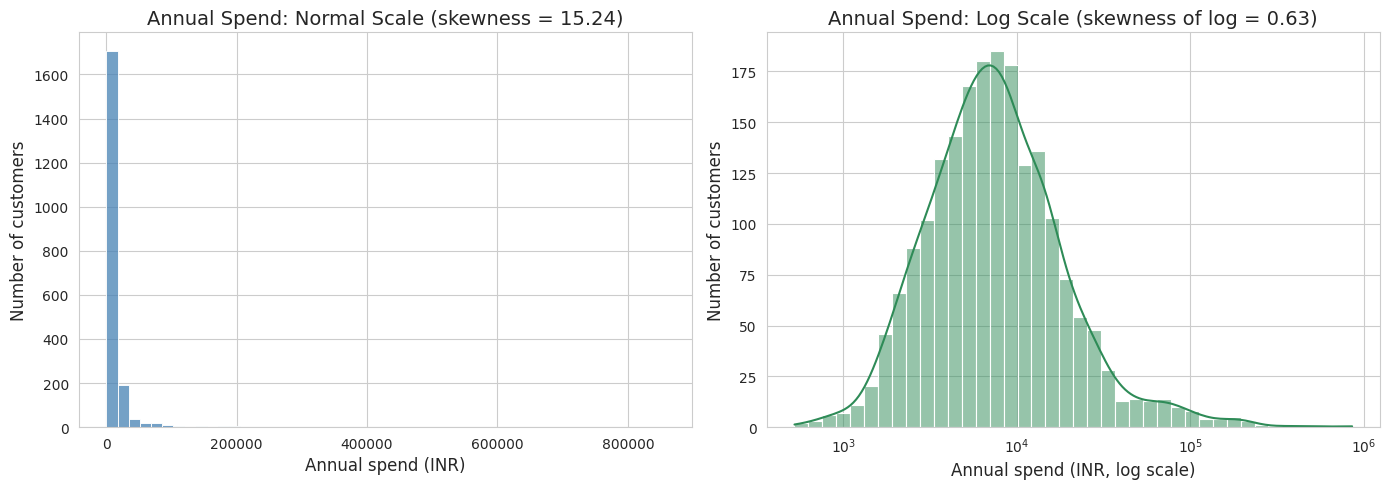

In [161]:
# Chart 25: annual_spend on a normal scale vs a log scale
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: normal scale (all the data is crowded at the left)
sns.histplot(df["annual_spend"], bins=50, color="steelblue", ax=axes[0])
axes[0].set_title(f"Annual Spend: Normal Scale (skewness = {df['annual_spend'].skew():.2f})")
axes[0].set_xlabel("Annual spend (INR)")
axes[0].set_ylabel("Number of customers")

# Right: log scale (bins are evenly spaced in multiples, not in rupees)
sns.histplot(df["annual_spend"], bins=40, log_scale=True, kde=True, color="seagreen", ax=axes[1])
axes[1].set_title(f"Annual Spend: Log Scale (skewness of log = {np.log(df['annual_spend']).skew():.2f})")
axes[1].set_xlabel("Annual spend (INR, log scale)")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

### Conclusion of Task 7: Pareto and the 80/20 Rule

**What I found**
| Question | Result |
|---|---|
| Customers needed for 50% of revenue | 238 customers = **11.9%** |
| Customers needed for 80% of revenue | 862 customers = **43.1%** |
| Revenue share of the top 20% of customers | **60.6%** |
| Revenue share of the bottom 50% of customers | about 15.9% |

**Comparison with the 80/20 rule:** The classic rule says the top 20% of customers produce about 80% of revenue. In this data the top 20% produce **60.6%**, and it takes the top **43.1%** to reach 80%. So revenue is strongly concentrated, but **less extreme than the classic 80/20 rule**. This agrees with the expected ballpark of about 60%. The result is robust: removing the single largest customer (855,443 INR, about 3.3% of revenue) leaves the top-20% share at 59.3%.

**Normal vs log scale:** On the normal scale almost all customers pile up at the left and the tail is invisible, because a few huge values stretch the axis. On the log scale each step is a multiple (for example 1,000 to 10,000 to 100,000) rather than an equal rupee amount, so both small and large spenders become visible and the shape becomes roughly bell-shaped (skewness falls from 15.24 to 0.63). A log scale is the right choice for data driven by multiplication, such as spend.

**Business meaning**
- About 400 customers (the top 20%, each spending at least 14,589 INR) generate 61% of revenue. Retaining them should be a priority, for example through loyalty perks or personal service.
- The bottom half of customers contribute only about 16% of revenue, so moving moderate customers to higher order frequency (the strongest driver in Task 4) is the main growth opportunity.

---
## Task 8: PDF and CDF
**Plan:** For delivery_time_min, plot the PDF (histogram + KDE) and the empirical CDF, then use the CDF to answer probability questions. Repeat for age, and compare the shapes of the two CDFs.

- **PDF** shows how densely the values are packed around each point.
- **CDF** shows the share of values at or below each point.

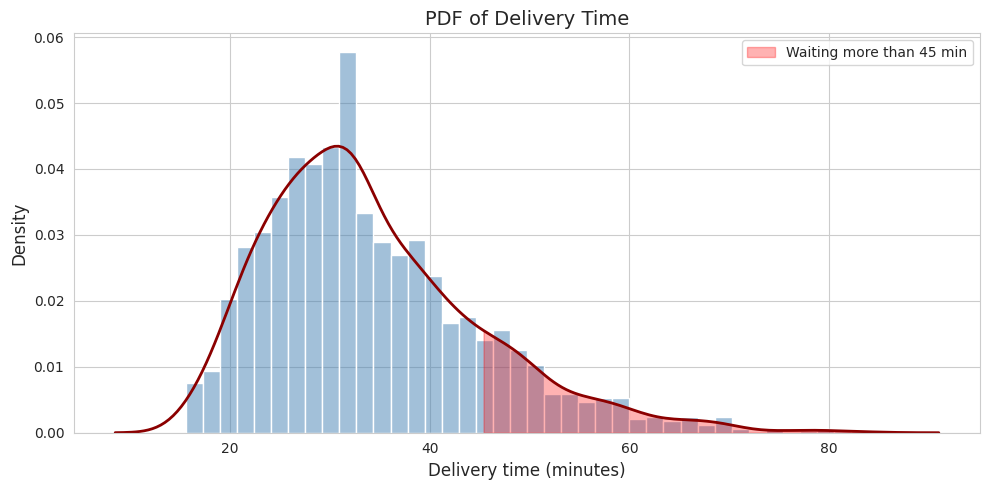

In [162]:
# Chart 26: PDF of delivery time (normalised histogram + KDE curve)
delivery = df["delivery_time_min"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(delivery, stat="density", bins=40, color="steelblue", alpha=0.5, ax=ax)
sns.kdeplot(delivery, color="darkred", linewidth=2, ax=ax)

# Shade the part of the curve beyond 45 minutes: the area under the curve = probability
x, y = ax.lines[0].get_data()
mask = x > 45
ax.fill_between(x[mask], y[mask], color="red", alpha=0.3, label="Waiting more than 45 min")

ax.set_title("PDF of Delivery Time")
ax.set_xlabel("Delivery time (minutes)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

In [163]:
# Empirical CDF: sort the values, then give the i-th smallest value a cumulative
# probability of i/n (as the task suggests)
x_del = np.sort(delivery.values)
n = len(x_del)
cdf_del = np.arange(1, n + 1) / n

# Probability of a delivery <= 30 minutes: share of values at or below 30
p_le_30 = np.searchsorted(x_del, 30, side="right") / n

# Probability of a delivery > 45 minutes: 1 minus the share at or below 45
p_gt_45 = 1 - np.searchsorted(x_del, 45, side="right") / n

# Median and 95th percentile: first value where the CDF reaches 0.50 and 0.95
median_del = x_del[np.argmax(cdf_del >= 0.50)]
p95_del = x_del[np.argmax(cdf_del >= 0.95)]

print(f"P(delivery <= 30 min) = {p_le_30:.4f}  ({p_le_30 * 100:.1f}%)")
print(f"P(delivery > 45 min)  = {p_gt_45:.4f}  ({p_gt_45 * 100:.1f}%)")
print(f"Median delivery time (CDF = 0.50): {median_del:.1f} minutes")
print(f"95th percentile (CDF = 0.95):      {p95_del:.1f} minutes")

P(delivery <= 30 min) = 0.3985  (39.9%)
P(delivery > 45 min)  = 0.1560  (15.6%)
Median delivery time (CDF = 0.50): 32.2 minutes
95th percentile (CDF = 0.95):      55.0 minutes


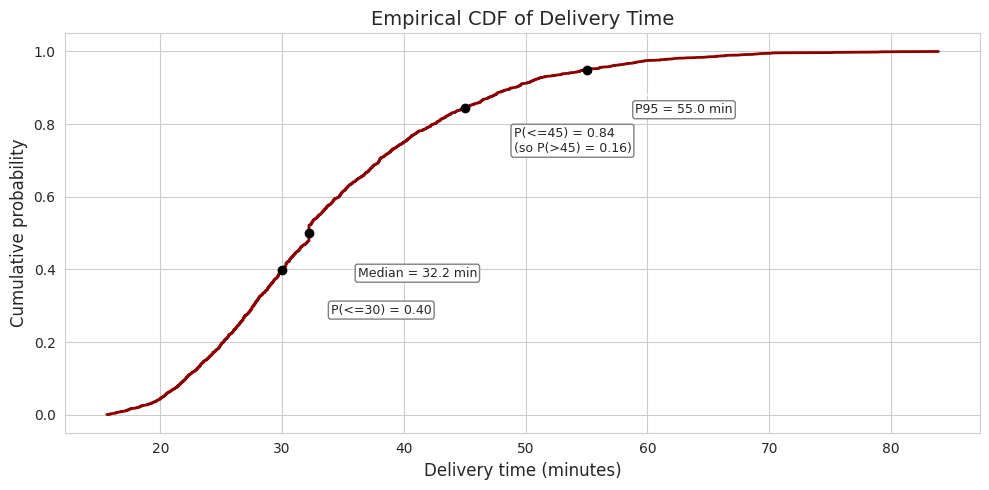

In [164]:
# Chart 27: empirical CDF of delivery time with the answers marked
plt.figure(figsize=(10, 5))
plt.plot(x_del, cdf_del, color="darkred", linewidth=2)

# Mark the key points read from the curve
plt.scatter([30, 45, median_del, p95_del],
            [p_le_30, 1 - p_gt_45, 0.50, 0.95], color="black", zorder=5)
for xv, yv, text in [(30, p_le_30, f"P(<=30) = {p_le_30:.2f}"),
                     (45, 1 - p_gt_45, f"P(<=45) = {1 - p_gt_45:.2f}\n(so P(>45) = {p_gt_45:.2f})"),
                     (median_del, 0.50, f"Median = {median_del:.1f} min"),
                     (p95_del, 0.95, f"P95 = {p95_del:.1f} min")]:
    plt.annotate(text, xy=(xv, yv), xytext=(xv + 4, yv - 0.12),
                 arrowprops=dict(arrowstyle="->"), fontsize=9,
                 bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.2"))

plt.title("Empirical CDF of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Cumulative probability")
plt.tight_layout()
plt.show()

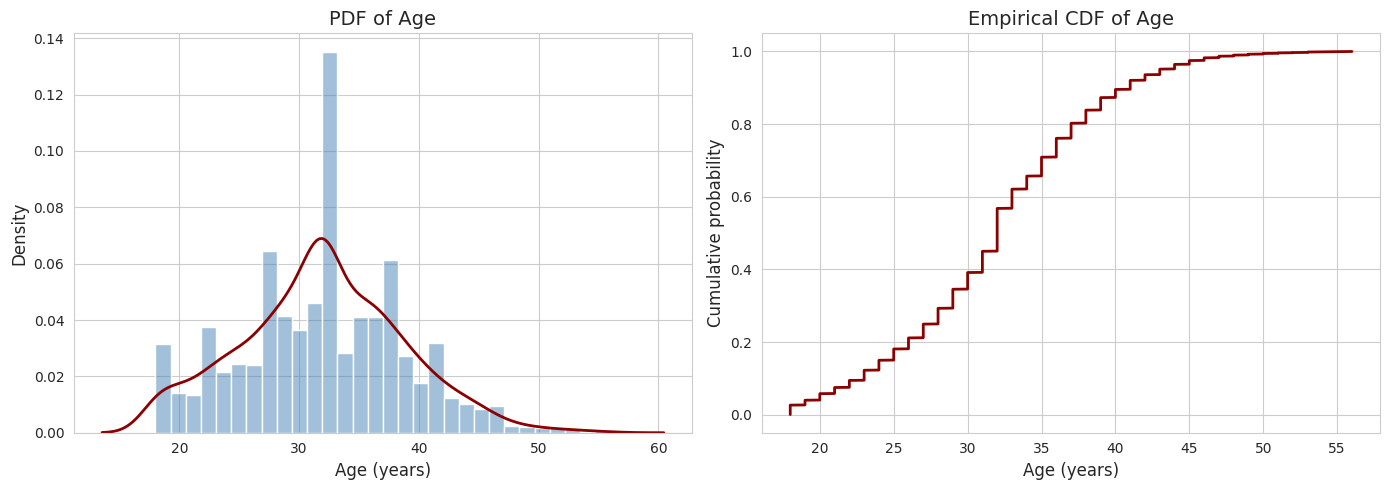

P(age <= 30) = 0.3915
P(age > 45)  = 0.0250
Median age = 32 | 95th percentile = 43


In [165]:
# Repeat the same analysis for age
age = df["age"]
x_age = np.sort(age.values)
cdf_age = np.arange(1, n + 1) / n          # same n = 2000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 28: PDF of age
sns.histplot(age, stat="density", bins=30, color="steelblue", alpha=0.5, ax=axes[0])
sns.kdeplot(age, color="darkred", linewidth=2, ax=axes[0])
axes[0].set_title("PDF of Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")

# Chart 29: empirical CDF of age
axes[1].plot(x_age, cdf_age, color="darkred", linewidth=2)
axes[1].set_title("Empirical CDF of Age")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Cumulative probability")

plt.tight_layout()
plt.show()

# Probability answers for age, read from the CDF
p_age_le_30 = np.searchsorted(x_age, 30, side="right") / n
p_age_gt_45 = 1 - np.searchsorted(x_age, 45, side="right") / n
median_age = x_age[np.argmax(cdf_age >= 0.50)]
p95_age = x_age[np.argmax(cdf_age >= 0.95)]

print(f"P(age <= 30) = {p_age_le_30:.4f}")
print(f"P(age > 45)  = {p_age_gt_45:.4f}")
print(f"Median age = {median_age:.0f} | 95th percentile = {p95_age:.0f}")

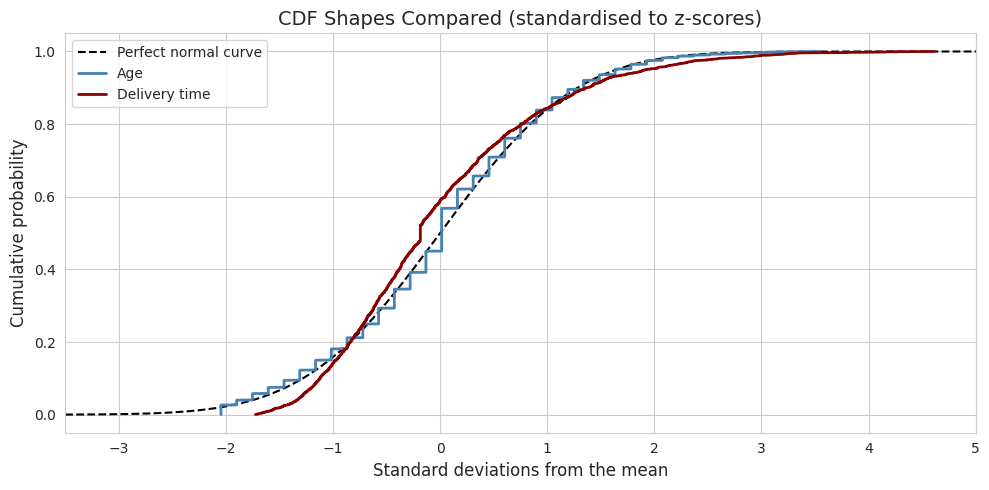

In [166]:
# Chart 30: compare CDF shapes. Age and delivery time have different units,
# so convert both to z-scores (distance from the mean in standard deviations).
from scipy.stats import norm

z_del = (x_del - x_del.mean()) / x_del.std()
z_age = (x_age - x_age.mean()) / x_age.std()
z_grid = np.linspace(-3.5, 6, 400)

plt.figure(figsize=(10, 5))
plt.plot(z_grid, norm.cdf(z_grid), color="black", linestyle="--", label="Perfect normal curve")
plt.plot(z_age, cdf_age, color="steelblue", linewidth=2, label="Age")
plt.plot(z_del, cdf_del, color="darkred", linewidth=2, label="Delivery time")
plt.xlim(-3.5, 5)
plt.title("CDF Shapes Compared (standardised to z-scores)")
plt.xlabel("Standard deviations from the mean")
plt.ylabel("Cumulative probability")
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion of Task 8: PDF and CDF

**In plain language**
- **PDF:** shows how *densely* values are packed around a point. A tall part of the curve means many customers have values near that point. The area under the curve between two points is the probability of falling between them.
- **CDF:** shows the *share of values at or below* a point. It always starts at 0, rises, and ends at 1, so reading it at any value tells you "what fraction of customers are at or below this?"

**Delivery time (read from the CDF)**
| Question | Answer |
|---|---|
| P(delivery <= 30 min) | 0.3985 (about 40%) |
| P(delivery > 45 min) | 0.156 (about 16%) |
| Median delivery time | about 32.2 minutes |
| 95th percentile | about 55.0 minutes |

So roughly **1 in 6 customers waits more than 45 minutes**, and 1 in 20 waits about 55 minutes or longer. This answers case-study question 5.

**Age**
| Question | Answer |
|---|---|
| P(age <= 30) | about 0.39 |
| P(age > 45) | about 0.025 |
| Median / 95th percentile | 32 / 43 |

**Comparing the shapes:** The age CDF is a smooth, symmetric S-curve that follows the normal curve, confirming an approximately normal distribution. The delivery CDF rises steeply and then flattens slowly, which is typical of right-skewed data with a tail of slow deliveries.

**Note:** Small steps at 32 (age) and 32.2 (delivery) in the CDFs come from filling missing values with the median in Task 1.

---
# QuickBite Customer Value: Summary for the Head of Growth

**What we did:** We reviewed 2,000 customers. We fixed missing entries (up to 13% in some fields) and corrected 11 clearly wrong entries, such as ages of 0 and 150, delivery times of up to 500 minutes, and order values of up to 32,000 INR. No customers were deleted, and the cleaned file is ready to use.

## Five key insights

1. **A small group drives most of the revenue.** The top 20% of customers (about 400 people, each spending at least 14,600 INR a year) bring in **61% of revenue**. Just 12% of customers bring in half of it, while the bottom half brings in only 16%.

2. **The "average customer" figure is misleading.** The average spend is about 13,000 INR a year, but a typical customer spends about **7,100 INR**. Only 1 in 4 customers spends more than the average.

3. **How often customers order matters most.** Number of orders has by far the strongest link with annual spend (0.72 on a scale where 1 is a perfect link), followed by basket size (0.25). App opens, discounts, ratings and delivery time show almost no link.

4. **Higher memberships spend more, but most customers are Basic.** Typical yearly spend rises from about 5,900 INR (Basic) to 12,400 INR (Platinum), yet **59% of customers are on Basic**.

5. **Delivery is usually fine, but unhappy customers go quiet.** A typical delivery takes 32 minutes and 9 in 10 arrive within 49 minutes, but **1 in 6 customers waits more than 45 minutes**. Lower-tier cities are about 6 minutes slower than metros (37 vs 31 minutes). Customers who left no rating waited about 8 minutes longer, so the 4.3 average rating probably looks better than real satisfaction.

## Two recommendations

1. **Protect the top 20% and raise order frequency among everyone else.** Offer the top group retention perks such as priority support. For mid-spenders, test frequency-based offers such as order streaks and membership upgrade nudges. The data shows these factors move together with spend, but it does not prove cause, so test on a small group before rolling out.

2. **Fix the slow-delivery tail and listen to quiet customers.** Focus delivery improvements on Tier 2 and Tier 3 cities, and send a short feedback request after every delivery over 45 minutes, so unhappy customers are heard even when they do not leave a rating.

---
## Final Conclusion: Answers to the Five Questions

| # | Question | Answer | Where |
|---|---|---|---|
| 1 | How much data is missing or wrong, and how was it fixed? | Six columns had 4.0% to 12.9% missing values. 11 impossible or extreme values were set to missing (3 ages, 4 delivery times, 4 order values). All gaps were filled using medians (group medians for order value and rating) and an "Unknown" category for gender. | Tasks 0, 1, 2 |
| 2 | What do the distributions look like? | Age is approximately normal; rating is left-skewed; delivery time and order value are right-skewed (order value is log-normal); annual spend and orders have heavy right tails. | Task 3 |
| 3 | Which variables move together with annual_spend? | Orders in the last 12 months (r = 0.72) by far; then average order value (0.25). Correlation does not prove causation. | Task 4 |
| 4 | How concentrated is revenue? | Top 20% of customers produce 60.6% of revenue; 11.9% produce half; 43.1% produce 80%. Strong, but weaker than a classic 80/20 split. | Task 7 |
| 5 | How likely is a wait of more than 45 minutes? | About 15.6% (roughly 1 in 6). | Task 8 |

In [167]:
# Final check: reload the saved clean file and confirm it is ready to submit
final = pd.read_csv("/content/quickbite_clean.csv")

print("Shape:", final.shape)                                   # expect (2000, 18)
print("Total missing values:", final.isna().sum().sum())       # expect 0
print("Duplicate customer IDs:", final["customer_id"].duplicated().sum())   # expect 0
print("Age range:", final["age"].min(), "to", final["age"].max())           # expect 18 to 56
print("Max delivery time:", final["delivery_time_min"].max())              # expect 83.9
print("Max order value:", final["avg_order_value"].max())                  # expect 1729.0

Shape: (2000, 18)
Total missing values: 0
Duplicate customer IDs: 0
Age range: 18.0 to 56.0
Max delivery time: 83.9
Max order value: 1729.0
